# Lab 01 - Ridge Regression: dự đoán `Post_Semester_GPA`

Notebook này gồm các phần 0-8 trong `Ridge_notebook_task.md`: setup, load dữ liệu, EDA phục vụ Ridge (chỉ train), pipeline tiền xử lý, baseline, quét α, vì sao Ridge, diễn giải hệ số, ablation Anxiety, đánh giá trên test (phần 9). Các phần sau (xuất App, kết luận) sẽ được thêm tiếp.

Quy ước: test chỉ được chạm một lần ở phần 9. Ở các phần này, cột target của test **không được đọc vào bộ nhớ**.

## Phần 0 - Setup và CONFIG

In [1]:
import hashlib, json, platform, sys, warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").is_file() and (p / "data/train/dataset.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Khong tim thay repo root (pyproject.toml + data/train/dataset.csv)")
sys.path.insert(0, str(ROOT / "src"))

from lab01_ml.models.ridge import (ANX, BIN, CAT, FORBIDDEN, NUM, TARGET, ClippedRegressor,
                                    make_model, make_preprocessor, make_X)

SEED = 42
np.random.seed(SEED)

DATA = ROOT / "data"
OUT = ROOT / "outputs" / "ridge"
FIG = OUT / "figures"
RES = OUT / "tables"
MODELS = OUT / "models"
for d in (FIG, RES, MODELS):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
sns.set_theme(style="whitegrid")
print("DATA :", DATA)
print("FIG  :", FIG)

DATA : /Users/thaihoang78/Workspace/04_Courses/CSC14005_Machine_Learning/ML-24KHMT2-Lab01/data
FIG  : /Users/thaihoang78/Workspace/04_Courses/CSC14005_Machine_Learning/ML-24KHMT2-Lab01/outputs/ridge/figures


# Parameters configuration: 

In [2]:
CONFIG = {
    # --- Quyet dinh mo hinh (D2-D8): truyen vao make_preprocessor / make_model, dung o moi phan tu 3 tro di ---
    "use_anxiety":    False,                    # D2 (ban chinh; phan 8 chay ca hai)
    "drop_first":     True,                     # D3
    "scale_onehot":   False,                    # D4
    "genai_mode":     "raw",                    # D5: "raw" | "log1p" | "raw+sq"
    "alpha_grid":     np.logspace(-2, 5, 50),
    "alpha_rule":     "1se",                    # D6: "min" | "1se"
    "clip_upper":     4.0,                      # D7: None neu khong clip
    "refit_on_trval": False,                    # D8: fit trên train + val hay chỉ train

    # --- Bootstrap ---
    "n_boot_train":   200,                      # for boostraping from training dataset (SD, rel). Dung o: 6.1
    "n_boot_val":     500,                      # for boostraping RMSE from validation. Dung o: 5.2, 5.3, phan 8

    # --- Phan 1-2: sanity check va EDA (chi dung train) ---
    "expected_n_rows":    (35_000, 7_500, 7_500),  # so dong train / val / test, assert sau khi load. Dung o: phan 1
    "gpa_cap":            4.0,                  # tran GPA cua du lieu (dac diem du lieu, khac clip_upper la quyet dinh). Dung o: 2.1, 9.5
    "gpa_cap_frac_range": (0.09, 0.10),         # khoang hop ly cua ty le dong GPA = gpa_cap (EDA nhom: 9.6%). Dung o: 2.1 (assert)
    "rare_threshold":     1000,                 # nhom co it mau hon so nay la nhom hiem. Dung o: 2.3, 6.1.4, 6.1.5
    "n_top_corr":         10,                   # so bien hien thi trong top |Pearson| voi target. Dung o: 2.4
    "vif_threshold":      5,                    # duong nguong VIF ve tren bieu do. Dung o: 2.5
    "n_deciles":          10,                   # so nhom (decile) chia Weekly_GenAI_Hours. Dung o: 2.6

    # --- So lieu doi chieu va dung sai cua cac GATE (assert fail neu lech) ---
    "ref_pearson_pre":    0.92641,              # EDA nhom: Pearson(Pre_Semester_GPA, target). Dung o: 2.4 (GATE 2)
    "tol_pearson_pre":    5e-4,                 # dung sai cua so tren. Dung o: 2.4 (GATE 2)
    "ref_max_vif":        2.77,                 # EDA nhom: max VIF. Dung o: 2.5 (GATE 2)
    "ref_cond_std":       4.32,                 # EDA nhom: condition number sau khi scale moi cot. Dung o: 2.5 (GATE 2)
    "tol_vif_cond":       0.05,                 # dung sai chung cho max VIF va condition number. Dung o: 2.5 (GATE 2)
    "ref_skew_genai":     1.61,                 # EDA nhom: skewness GenAI Hours (chi in de doi chieu, khong assert). Dung o: 2.6
    "tol_baseline_r2":    0.01,                 # |R2 val| cua mean baseline phai nho hon so nay. Dung o: 4.2
    "gate3_rmse_range":   (0.157, 0.1605),      # khoang RMSE OLS val (co clip <= khong clip). Dung o: 4.3 (GATE 3)
    "ref_e3_rmse":        0.157,                # EDA nhom: RMSE E3 (chi in de doi chieu, khong assert). Dung o: 4.3

    # --- 6.2 Learning curve ---
    "lc_n_grid":           [100, 200, 500, 1_000, 5_000, 35_000],  # cac co mau con n; phan tu cuoi = ca train (chay 1 lan). Dung o: 6.2
    "lc_n_rep":            20,                  # so lan lap cho moi n. Dung o: 6.2, 6.2.4
    "lc_inner_train_frac": 0.8,                 # ty le mau con dung de fit khi chon alpha noi bo (phan con lai la giu lai). Dung o: 6.2

    # --- Phan 7: bieu do he so ---
    "n_coef_path_labels": 8,                    # so he so duoc dan nhan tren coefficient path. Dung o: 7.1
    "n_coef_bar":         15,                   # so he so lon nhat hien thi o bieu do OLS vs Ridge. Dung o: 7.2
}

In [3]:
FILES = {
    "train": DATA / "train" / "dataset.csv",
    "validation": DATA / "validation" / "dataset.csv",
    "test": DATA / "test" / "dataset.csv",
}
with open(DATA / "metadata.json") as f:
    META = json.load(f)

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def verify_hashes(files, expected):
    for split, path in files.items():
        got, want = sha256_of(path), expected[f"{split}/dataset.csv"]
        if got != want:
            raise ValueError(f"SHA-256 sai cho {split}: {got} != {want}")

verify_hashes(FILES, META["dataset_sha256"])
print("Dữ liệu khớp metadata ✓")

Dữ liệu khớp metadata ✓


In [4]:
# 0.3: thu co y sai hash de chac chan verify_hashes thuc su raise
tampered = {**META["dataset_sha256"], "train/dataset.csv": "0" * 64}
try:
    verify_hashes(FILES, tampered)
    raise AssertionError("verify_hashes KHONG raise khi hash sai")
except ValueError as e:
    print("Raise đúng như mong đợi:", str(e)[:60], "...")

Raise đúng như mong đợi: SHA-256 sai cho train: 9f2174454c59a1283e308b5a6b74c2f165f16 ...


In [5]:
print("CONFIG")
print(pd.Series({k: (f"{len(v)} giá trị log-spaced, {v.min():g} đến {v.max():g}" if k == "alpha_grid" else v)
                 for k, v in CONFIG.items()}, name="value").to_frame())

ver = pd.DataFrame({
    "đang dùng": {"python": platform.python_version(), "numpy": np.__version__,
                  "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "metadata.json": META["versions"],
})
ver["khớp"] = ver["đang dùng"] == ver["metadata.json"]
ver.loc["python", "khớp"] = platform.python_version().rsplit(".", 1)[0] == META["versions"]["python"].rsplit(".", 1)[0]  # chi can cung 3.13
print()
print(ver)
print("matplotlib", matplotlib.__version__, "| seaborn", sns.__version__, "| statsmodels", statsmodels.__version__)

CONFIG
                                                      value
use_anxiety                                           False
drop_first                                             True
scale_onehot                                          False
genai_mode                                              raw
alpha_grid           50 giá trị log-spaced, 0.01 đến 100000
alpha_rule                                              1se
clip_upper                                              4.0
refit_on_trval                                        False
n_boot_train                                            200
n_boot_val                                              500
expected_n_rows                         (35000, 7500, 7500)
gpa_cap                                                 4.0
gpa_cap_frac_range                              (0.09, 0.1)
rare_threshold                                         1000
n_top_corr                                               10
vif_threshold                    

## Phần 1 - Load và sanity check

In [6]:
# TARGET, NUM, BIN, CAT, ANX, FORBIDDEN dinh nghia trong src/lab01_ml/models/ridge.py (nguon duy nhat)
FEATURES_12 = NUM + BIN + CAT + [ANX]
assert len(FEATURES_12) == 12, len(FEATURES_12)

train = pd.read_csv(FILES["train"])
val = pd.read_csv(FILES["validation"])
# test: bo target ngay luc doc. target cua test chi duoc doc o phan 9.
test = pd.read_csv(FILES["test"]).drop(columns=[TARGET])

assert (len(train), len(val), len(test)) == CONFIG["expected_n_rows"], (len(train), len(val), len(test))
print("Số dòng train / val / test:", len(train), len(val), len(test))

Số dòng train / val / test: 35000 7500 7500


In [7]:
# 1.3 khong cot cam nao nam trong X
for flag in (False, True):
    X = make_X(train, flag)
    assert not set(FORBIDDEN) & set(X.columns), "co cot cam trong X"
    assert TARGET not in X.columns
print("Không có cột FORBIDDEN / TARGET trong X ✓")

# 1.4 Paid_Subscription bool -> 0/1
for df in (train, val, test):
    df["Paid_Subscription"] = df["Paid_Subscription"].astype(int)
assert all(df["Paid_Subscription"].isin([0, 1]).all() for df in (train, val, test))
print("Paid_Subscription dtype:", train["Paid_Subscription"].dtype)

Không có cột FORBIDDEN / TARGET trong X ✓
Paid_Subscription dtype: int64


In [8]:
# 1.5 moi category cua val/test deu co trong train
CAT_ALL = CAT + [ANX]
for name, df in (("validation", val), ("test", test)):
    for c in CAT_ALL:
        unseen = set(df[c].unique()) - set(train[c].unique())
        assert not unseen, f"{name}.{c} co category la: {unseen}"
print("Mọi category của val/test đều có trong train ✓")

# 1.6 / 1.7 missing, trung lap, bang tom tat
summary = pd.DataFrame({
    name: {"số dòng": len(df), "số cột": df.shape[1],
           "missing": int(df.isna().sum().sum()), "trùng lặp": int(df.duplicated().sum())}
    for name, df in (("train", train), ("validation", val), ("test (không target)", test))
})
print(summary)
assert summary.loc[["missing", "trùng lặp"]].to_numpy().sum() == 0

Mọi category của val/test đều có trong train ✓
           train  validation  test (không target)
số dòng    35000        7500                 7500
số cột        16          16                   15
missing        0           0                    0
trùng lặp      0           0                    0


**GATE 1:** SHA-256 khớp (phần 0), số dòng đúng, không có cột cấm trong X. Cả ba đã được assert ở trên.

## Phần 2 - EDA phục vụ Ridge (chỉ train)

Mỗi mục trả lời một câu hỏi gắn với Ridge. Chỉ dùng `train`. Số liệu phải khớp EDA nhóm.

### 2.1 Target có bị chặn trần không?

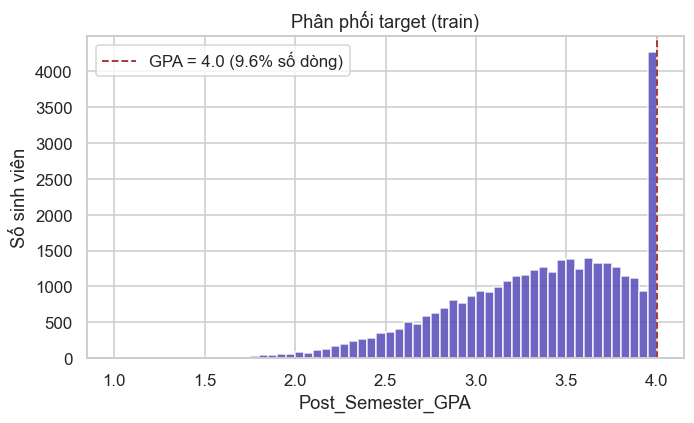

Số dòng GPA = 4.0: 3369 (9.63%); min=1.0, max=4.0


In [9]:
y = train[TARGET]
frac_cap = (y == CONFIG["gpa_cap"]).mean()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(y, bins=60, color="#534AB7", alpha=0.85)
ax.axvline(CONFIG["gpa_cap"], color="#A32D2D", ls="--", lw=1.2, label=f"GPA = {CONFIG['gpa_cap']} ({frac_cap:.1%} số dòng)")
ax.set(xlabel=TARGET, ylabel="Số sinh viên", title="Phân phối target (train)")
ax.legend()
fig.savefig(FIG / "eda_2_1_target_hist.png")
plt.show()
print(f"Số dòng GPA = {CONFIG['gpa_cap']}: {(y == CONFIG['gpa_cap']).sum()} ({frac_cap:.2%}); min={y.min()}, max={y.max()}")
lo, hi = CONFIG["gpa_cap_frac_range"]
assert lo < frac_cap < hi

### 2.2 Các biến số có cùng thang đo không?

                           mean    std    min     max
Pre_Semester_GPA          3.146  0.478  1.183   3.998
Traditional_Study_Hours  11.202  5.162  1.000  35.860
Weekly_GenAI_Hours        8.445  8.317  0.000  40.000
Tool_Diversity            2.797  1.186  1.000   5.000


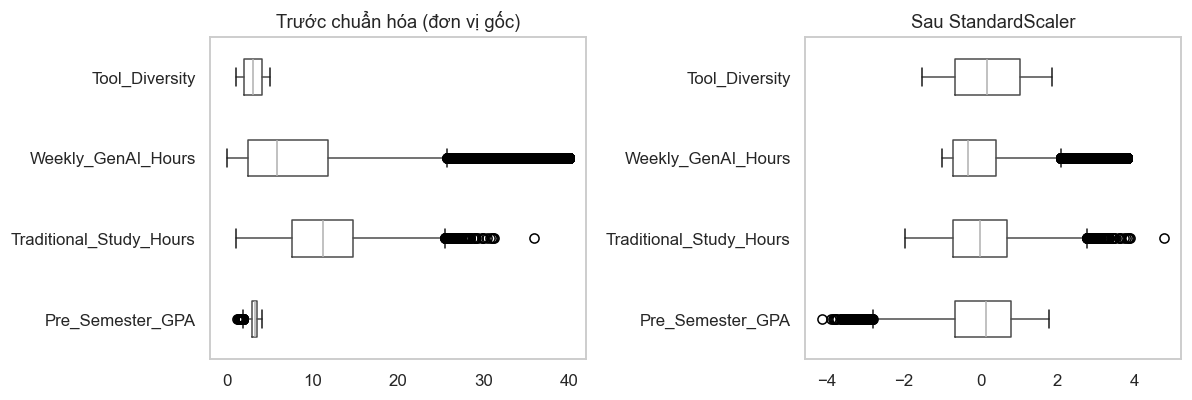

In [10]:
num_all = NUM
desc = train[num_all].agg(["mean", "std", "min", "max"]).T.round(3)
print(desc)

scaled = pd.DataFrame(StandardScaler().fit_transform(train[num_all]), columns=num_all)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
train[num_all].boxplot(ax=axes[0], vert=False, grid=False)
axes[0].set(title="Trước chuẩn hóa (đơn vị gốc)")
scaled.boxplot(ax=axes[1], vert=False, grid=False)
axes[1].set(title="Sau StandardScaler")
fig.tight_layout()
fig.savefig(FIG / "eda_2_2_scale.png")
plt.show()

### 2.3 Có nhóm hiếm không?

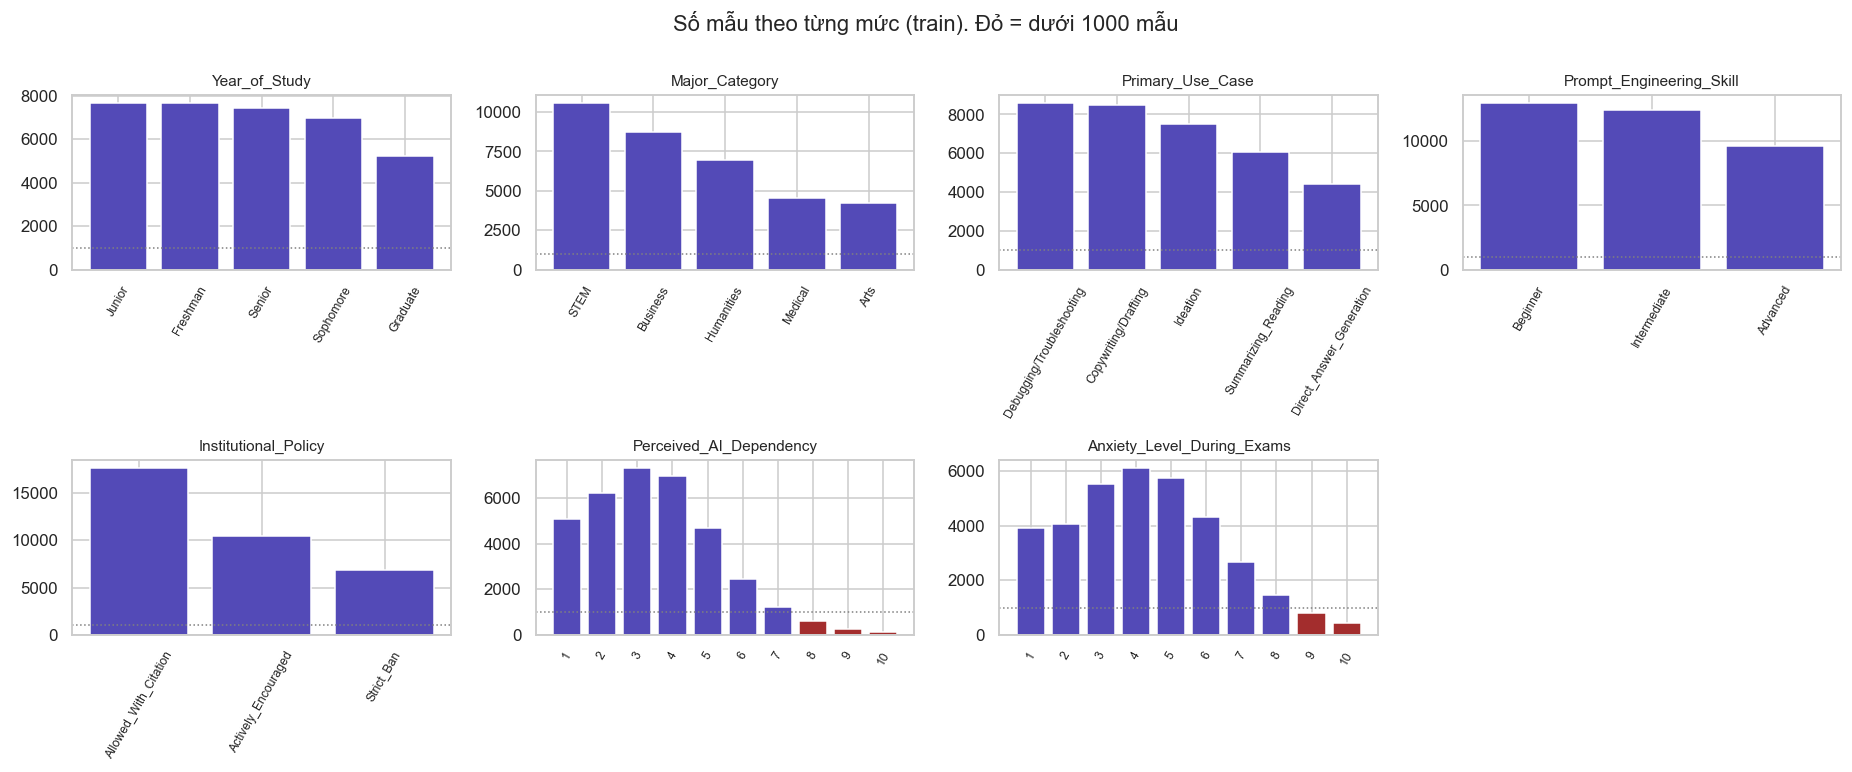

5 mức có dưới 1000 mẫu:
                  variable level   n
   Perceived_AI_Dependency    10 138
   Perceived_AI_Dependency     9 270
Anxiety_Level_During_Exams    10 421
   Perceived_AI_Dependency     8 622
Anxiety_Level_During_Exams     9 803


In [11]:
rows = [(c, lvl, int(n)) for c in CAT_ALL for lvl, n in train[c].value_counts().items()]
group_counts = pd.DataFrame(rows, columns=["variable", "level", "n"])
group_counts.to_csv(RES / "group_counts.csv", index=False)     # task 6.1 dung lai

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), CAT_ALL):
    s = train[c].value_counts()
    s = s.sort_index() if c in ("Perceived_AI_Dependency", ANX) else s.sort_values(ascending=False)
    ax.bar(s.index.astype(str), s.values, color=np.where(s.values < CONFIG["rare_threshold"], "#A32D2D", "#534AB7"))
    ax.axhline(CONFIG["rare_threshold"], color="grey", ls=":", lw=1)
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="x", rotation=60, labelsize=8)
for ax in axes.ravel()[len(CAT_ALL):]:
    ax.axis("off")
fig.suptitle(f"Số mẫu theo từng mức (train). Đỏ = dưới {CONFIG['rare_threshold']} mẫu", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "eda_2_3_group_counts.png")
plt.show()

rare = group_counts[group_counts["n"] < CONFIG["rare_threshold"]].sort_values("n")
print(f"{len(rare)} mức có dưới {CONFIG['rare_threshold']} mẫu:")
print(rare.to_string(index=False))

### 2.4 Biến nào liên hệ mạnh với target?

                                            pearson  spearman
feature                                                      
Pre_Semester_GPA                             0.9265    0.9172
Traditional_Study_Hours                      0.1399    0.1426
Year_of_Study_Freshman                      -0.0745   -0.0758
Prompt_Engineering_Skill_Advanced            0.0504    0.0540
Primary_Use_Case_Debugging/Troubleshooting   0.0504    0.0540
Year_of_Study_Senior                         0.0418    0.0439
Primary_Use_Case_Direct_Answer_Generation   -0.0381   -0.0363
Year_of_Study_Graduate                       0.0352    0.0354
Tool_Diversity                               0.0263    0.0305
Prompt_Engineering_Skill_Beginner           -0.0244   -0.0242


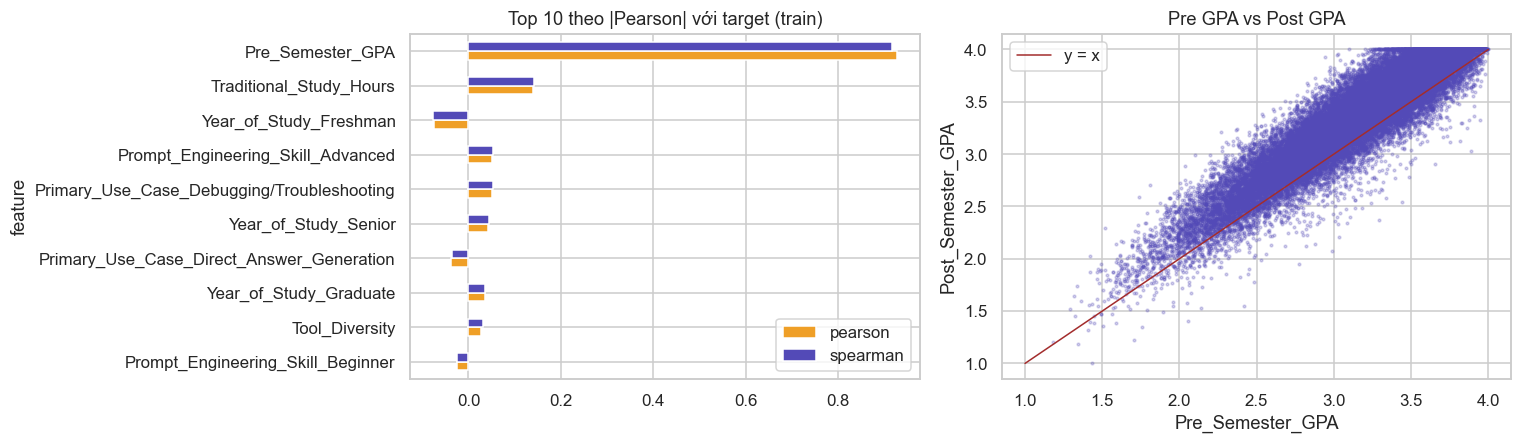

Pearson Pre GPA = 0.92648 (EDA nhóm: 0.92641)


In [12]:
D = pd.get_dummies(train[NUM + BIN + CAT_ALL], columns=CAT_ALL, dtype=float)
rows = []
for c in D.columns:
    rows.append((c, stats.pearsonr(D[c], y)[0], stats.spearmanr(D[c], y)[0]))
corr = pd.DataFrame(rows, columns=["feature", "pearson", "spearman"]).set_index("feature")
top_corr = corr.reindex(corr["pearson"].abs().sort_values(ascending=False).index).head(CONFIG["n_top_corr"])
print(top_corr.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
top_corr.iloc[::-1].plot.barh(ax=axes[0], color=["#EF9F27", "#534AB7"])
axes[0].set(title=f"Top {CONFIG['n_top_corr']} theo |Pearson| với target (train)")
axes[1].scatter(train["Pre_Semester_GPA"], y, s=3, alpha=0.25, color="#534AB7")
lim = [1, 4]
axes[1].plot(lim, lim, color="#A32D2D", lw=1, label="y = x")
axes[1].set(xlabel="Pre_Semester_GPA", ylabel=TARGET, title="Pre GPA vs Post GPA")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "eda_2_4_correlation.png")
plt.show()

pearson_pre = corr.loc["Pre_Semester_GPA", "pearson"]
print(f"Pearson Pre GPA = {pearson_pre:.5f} (EDA nhóm: {CONFIG['ref_pearson_pre']:.5f})")
assert abs(pearson_pre - CONFIG["ref_pearson_pre"]) < CONFIG["tol_pearson_pre"]

### 2.5 Có đa cộng tuyến không?

p = 39 | rank = 39
Top 5 VIF:
Major_Category_STEM                  2.759
Major_Category_Business              2.515
Prompt_Engineering_Skill_Beginner    2.325
Weekly_GenAI_Hours                   2.199
Anxiety_Level_During_Exams_4         2.143
dtype: float64
Condition number: không scale = 288.2 | scale biến số = 23.0 | scale mọi cột = 4.33 (EDA nhóm: 4.32)
Max VIF = 2.759 (EDA nhóm: 2.77). p = 39 cột + intercept = 40 (EDA nhóm ghi 40/40)


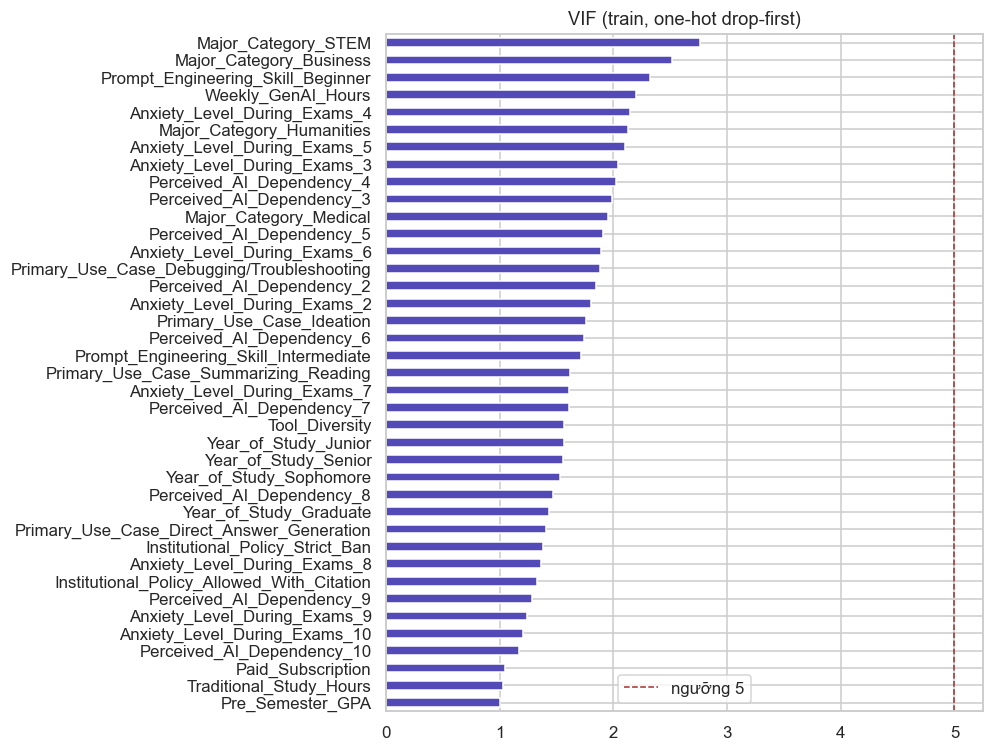

In [13]:
# Ma tran giong E3 cua EDA nhom: 12 feature (co Anxiety), one-hot drop-first
Xd = pd.get_dummies(train[NUM + BIN + CAT_ALL], columns=CAT_ALL, drop_first=True, dtype=float)
Xd[NUM] = StandardScaler().fit_transform(Xd[NUM])
Xc = np.column_stack([np.ones(len(Xd)), Xd.to_numpy()])
vif = pd.Series([variance_inflation_factor(Xc, i + 1) for i in range(Xd.shape[1])], index=Xd.columns)
print("p =", Xd.shape[1], "| rank =", np.linalg.matrix_rank(Xd.to_numpy()))
print("Top 5 VIF:"); print(vif.sort_values(ascending=False).head(5).round(3))

raw = pd.get_dummies(train[NUM + BIN + CAT_ALL], columns=CAT_ALL, drop_first=True, dtype=float)
cond_raw = np.linalg.cond(raw.to_numpy())
cond_num = np.linalg.cond(Xd.to_numpy())                              # chi scale bien so
cond_all = np.linalg.cond(StandardScaler().fit_transform(raw))        # scale moi cot (cach EDA nhom)
print(f"Condition number: không scale = {cond_raw:.1f} | scale biến số = {cond_num:.1f} | scale mọi cột = {cond_all:.2f} (EDA nhóm: {CONFIG['ref_cond_std']:.2f})")
print(f"Max VIF = {vif.max():.3f} (EDA nhóm: {CONFIG['ref_max_vif']:.2f}). p = {Xd.shape[1]} cột + intercept = {Xd.shape[1] + 1} (EDA nhóm ghi 40/40)")
assert abs(vif.max() - CONFIG["ref_max_vif"]) < CONFIG["tol_vif_cond"] and abs(cond_all - CONFIG["ref_cond_std"]) < CONFIG["tol_vif_cond"]

fig, ax = plt.subplots(figsize=(7, 8))
vif.sort_values().plot.barh(ax=ax, color="#534AB7")
ax.axvline(CONFIG["vif_threshold"], color="#A32D2D", ls="--", lw=1, label=f"ngưỡng {CONFIG['vif_threshold']}")
ax.set(title="VIF (train, one-hot drop-first)"); ax.legend()
fig.savefig(FIG / "eda_2_5_vif.png")
plt.show()

### 2.6 GenAI Hours có phi tuyến không?

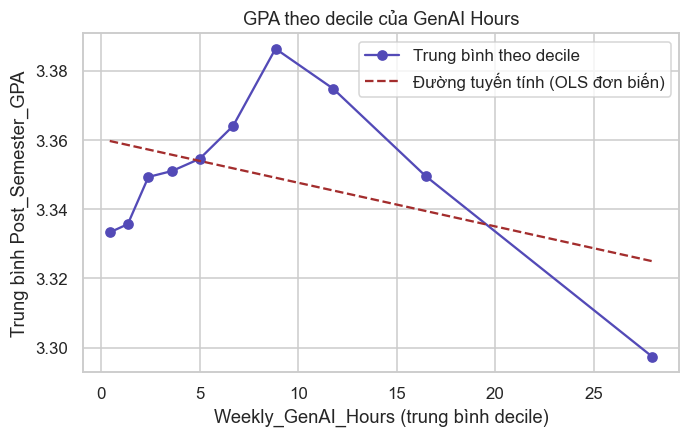

             h    gpa
decile               
0        0.430  3.333
1        1.344  3.336
2        2.392  3.349
3        3.589  3.351
4        4.993  3.354
5        6.691  3.364
6        8.847  3.386
7       11.768  3.375
8       16.464  3.350
9       27.975  3.297
Skewness GenAI Hours = 1.61 (EDA nhóm: 1.61)


In [14]:
g = train.assign(decile=pd.qcut(train["Weekly_GenAI_Hours"], CONFIG["n_deciles"], labels=False, duplicates="drop"))
agg = g.groupby("decile").agg(h=("Weekly_GenAI_Hours", "mean"), gpa=(TARGET, "mean"))
slope, intercept = np.polyfit(train["Weekly_GenAI_Hours"], y, 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(agg["h"], agg["gpa"], "o-", color="#534AB7", label="Trung bình theo decile")
xs = np.linspace(agg["h"].min(), agg["h"].max(), 50)
ax.plot(xs, intercept + slope * xs, "--", color="#A32D2D", label="Đường tuyến tính (OLS đơn biến)")
ax.set(xlabel="Weekly_GenAI_Hours (trung bình decile)", ylabel=f"Trung bình {TARGET}",
       title="GPA theo decile của GenAI Hours")
ax.legend()
fig.savefig(FIG / "eda_2_6_genai_decile.png")
plt.show()
print(agg.round(3))
print(f"Skewness GenAI Hours = {stats.skew(train['Weekly_GenAI_Hours']):.2f} (EDA nhóm: {CONFIG['ref_skew_genai']:.2f})")

### 2.7 Nhận xét 

- `Post_Semester_GPA` dồn ở trần 4.0 (9.63% số dòng train), nên mô hình tuyến tính có thể dự đoán vượt 4.0 và ta cân nhắc clip dự đoán. `Pre_Semester_GPA` là biến liên hệ mạnh nhất (Pearson 0.926), bỏ xa biến thứ hai là `Traditional_Study_Hours` (0.140).
- Độ lệch chuẩn của các biến số khác nhau nhiều (từ 0.478 đến 8.317) nên cần chuẩn hóa để mức phạt L2 không phụ thuộc đơn vị đo; với 39 cột (gồm Anxiety), max VIF chỉ 2.76 (< 5) và condition number là 4.33 khi scale mọi cột, tức đa cộng tuyến thấp.
- Có 5 mức dưới 1000 mẫu (ít nhất là `Perceived_AI_Dependency` = 10 với 138 mẫu), nên hệ số của chúng có thể kém ổn định. Ngoài ra `Weekly_GenAI_Hours` lệch phải (skewness 1.61) và GPA trung bình theo decile tăng từ 3.333 lên 3.386 (+0.006/giờ) rồi giảm còn 3.297 (-0.005/giờ), nên GPA có quan hệ phi tuyến nhẹ với feature GenAI.
- Với n = 35 000 và đa cộng tuyến thấp (Max VIF = 2.759), ta kỳ vọng Ridge khó cải thiện đáng kể RMSE so với OLS; lợi ích chủ yếu là co hệ số của nhóm hiếm, đổi lại hệ số bị co về 0 (được kiểm tra ở phần 5-6).

## Phần 3 - Preprocessing

- Biến số (`NUM`, trừ GenAI) -> `StandardScaler`.
- `Weekly_GenAI_Hours` -> biến đổi theo `genai_mode` (D5) rồi `StandardScaler`.
- Biến phân loại -> `OneHotEncoder(drop=..., handle_unknown="ignore")`; nếu `scale_onehot` thì scale thêm (D4).
- Biến nhị phân -> giữ nguyên, hoặc scale theo D4.

Mọi bước học tham số từ train bên trong `Pipeline`, nên không rò rỉ khi dùng với val/test.

Các lớp và hàm (`make_preprocessor`, `make_model`, `ClippedRegressor`, `GenAIPoly`) nằm trong `src/lab01_ml/models/ridge.py` để notebook và App dùng chung. Ô dưới đây chỉ import và kiểm tra chúng.

In [15]:
# Ma tran X va OLS dung lai o phan 4, 6, 7 (m_clip la OLS co clip)
Xtr, ytr = make_X(train, CONFIG["use_anxiety"]), train[TARGET]
m_clip = make_model(LinearRegression(), CONFIG).fit(Xtr, ytr)
m_raw = make_model(LinearRegression(), {**CONFIG, "clip_upper": None}).fit(Xtr, ytr)
Xva = make_X(val, CONFIG["use_anxiety"])
p_clip, p_raw = m_clip.predict(Xva), m_raw.predict(Xva)


In [16]:
# 3.3 test nho cua ClippedRegressor: du doan khong vuot clip_upper
print(f"max dự đoán: không clip = {p_raw.max():.3f}, có clip = {p_clip.max():.3f}")
assert p_raw.max() > CONFIG["clip_upper"], "khong clip thi phai co du doan > clip_upper de test co y nghia"
assert p_clip.max() <= CONFIG["clip_upper"]
assert np.allclose(p_clip, np.minimum(p_raw, CONFIG["clip_upper"]))
print("ClippedRegressor ✓")

max dự đoán: không clip = 4.353, có clip = 4.000
ClippedRegressor ✓


In [17]:
# 3.4 danh sach feature sau encode va so feature p
prep = make_preprocessor(CONFIG).fit(Xtr)
feat_names = prep.get_feature_names_out()
print("p =", len(feat_names))
print(*feat_names, sep='\n')

p = 30
Pre_Semester_GPA
Traditional_Study_Hours
Tool_Diversity
Weekly_GenAI_Hours
Year_of_Study_Graduate
Year_of_Study_Junior
Year_of_Study_Senior
Year_of_Study_Sophomore
Major_Category_Business
Major_Category_Humanities
Major_Category_Medical
Major_Category_STEM
Primary_Use_Case_Debugging/Troubleshooting
Primary_Use_Case_Direct_Answer_Generation
Primary_Use_Case_Ideation
Primary_Use_Case_Summarizing_Reading
Prompt_Engineering_Skill_Beginner
Prompt_Engineering_Skill_Intermediate
Institutional_Policy_Allowed_With_Citation
Institutional_Policy_Strict_Ban
Perceived_AI_Dependency_2
Perceived_AI_Dependency_3
Perceived_AI_Dependency_4
Perceived_AI_Dependency_5
Perceived_AI_Dependency_6
Perceived_AI_Dependency_7
Perceived_AI_Dependency_8
Perceived_AI_Dependency_9
Perceived_AI_Dependency_10
Paid_Subscription


In [18]:
# 3.5 fit tren train: mean cac cot so da scale ~ 0 tren train (val thi khong nhat thiet)
Ztr = pd.DataFrame(prep.transform(Xtr), columns=feat_names)
scaled_cols = [c for c in feat_names if c in NUM]
assert np.allclose(Ztr[scaled_cols].mean(), 0, atol=1e-9)
assert np.allclose(Ztr[scaled_cols].std(ddof=0), 1, atol=1e-9)
Zva = pd.DataFrame(prep.transform(Xva), columns=feat_names)
print("Train: mean ≈ 0, std ≈ 1 ✓")
print("Val: mean của cột số đã scale:")
print(Zva[scaled_cols].mean().round(4).to_frame(name="Val_Mean"))

Train: mean ≈ 0, std ≈ 1 ✓
Val: mean của cột số đã scale:
                         Val_Mean
Pre_Semester_GPA          -0.0025
Traditional_Study_Hours   -0.0015
Tool_Diversity             0.0130
Weekly_GenAI_Hours        -0.0059


In [19]:
# 3.6 doi drop_first / genai_mode / use_anxiety thi p thay doi dung nhu ky vong
def p_of(**over):
    cfg = {**CONFIG, **over}
    return len(make_preprocessor(cfg).fit(make_X(train, cfg["use_anxiety"])).get_feature_names_out())

n_lv = {c: train[c].nunique() for c in CAT_ALL}
base_cat = sum(n_lv[c] - 1 for c in CAT)                    # drop-first, khong Anxiety
p_base = 3 + 1 + base_cat + 1                               # num(3) + genai + cat + bin
expected = {
    "mặc định": ({}, p_base),
    "drop_first=False": ({"drop_first": False}, p_base + len(CAT)),
    "genai_mode=raw+sq": ({"genai_mode": "raw+sq"}, p_base + 1),
    "genai_mode=log1p": ({"genai_mode": "log1p"}, p_base),
    "scale_onehot=True": ({"scale_onehot": True}, p_base),
    "use_anxiety=True": ({"use_anxiety": True}, p_base + n_lv[ANX] - 1),
}
rows = []
for name, (over, exp) in expected.items():
    got = p_of(**over)
    rows.append((name, exp, got))
    assert got == exp, (name, exp, got)
print(pd.DataFrame(rows, columns=["cấu hình", "p kỳ vọng", "p thực tế"]).to_string(index=False))
print("Mọi thay đổi CONFIG cho p đúng như kỳ vọng ✓")

         cấu hình  p kỳ vọng  p thực tế
         mặc định         30         30
 drop_first=False         36         36
genai_mode=raw+sq         31         31
 genai_mode=log1p         30         30
scale_onehot=True         30         30
 use_anxiety=True         39         39
Mọi thay đổi CONFIG cho p đúng như kỳ vọng ✓


## Phần 4 - Baseline

> **Đọc trước khi xem kết quả phần 4 đến 8: các lựa chọn và giả định.**
>
> **Bạn đã chọn (khi tôi hỏi):**
> - **6.3 (tương tác bậc 2) bỏ qua**, vì A4 chưa chốt.
> - **Quét α (5.1)** tính RMSE trên dự đoán **đã clip** theo `CONFIG["clip_upper"]`. Phần 4 báo cả có và không clip.
> - **SE của RMSE (5.2)** = độ lệch chuẩn của RMSE bootstrap `CONFIG["n_boot_val"] = 500` lần trên dòng validation, đo **tại α_min**. Một SE chung cho mọi α. (`CONFIG["n_boot_train"] = 200` dùng cho bootstrap hệ số ở 6.1.)
> - **Learning curve (6.2)** chọn α nội bộ bằng **RMSE nhỏ nhất** trên 20% giữ lại. Cách này **khác** quy tắc 1-SE dùng ở phần 5, nên khi đọc 6.2 đừng so α ở hai chỗ như cùng một thứ.
>
> **Tôi tự chọn khi viết code (task file không nói rõ, bạn nên đọc lại và gật đầu hoặc sửa):**
> - 6.1: mỗi lần bootstrap fit lại **cả pipeline** (scaler, one-hot), không chỉ mô hình. Hệ số vẫn ở thang chuẩn hóa.
> - 6.1: "số mẫu nhóm" của biến số liên tục = 35.000 (cả train). Của `Paid_Subscription` = số dòng có giá trị 1.
> - 6.2: sau khi chọn α nội bộ, Ridge được **fit lại trên toàn bộ n dòng** của mẫu con rồi mới đo trên validation (OLS cũng fit trên toàn bộ n dòng). Validation **không** dùng để chọn α.
> - 6.2 ở n = 35.000: mẫu con chính là cả train nên chỉ chạy 1 lần (std ghi là 0). Cuối ô 6.2 có dòng so Ridge ở ALPHA đã chọn (5.3) với OLS.
> - 7.2: top 15 chọn theo |hệ số OLS|.
> - 8: bản có Anxiety dùng cùng lưới α, cùng `alpha_rule`, và SE được tính lại riêng cho bản đó.
>
> **Các ô bạn phải tự viết (đề trừ điểm nếu lạm dụng AI): 4.4, 5.7, 6.4, 7.5, 8.3.** Mỗi ô có hướng dẫn đọc lại phần nào. Tôi không viết sẵn nhận xét hay kết luận nào ở các ô đó.

### 4.1 Hàm tính MAE / MSE / RMSE / R²

In [20]:
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

yva = val[TARGET].to_numpy()
ytr_np = ytr.to_numpy()

### 4.2 Baseline: dự đoán bằng trung bình train

In [21]:
base = DummyRegressor(strategy="mean").fit(Xtr, ytr)
m_base = metrics(yva, base.predict(Xva))
print(f"Trung bình target train = {ytr.mean():.4f} | R2 val = {m_base['R2']:.5f}")
assert abs(m_base["R2"]) < CONFIG["tol_baseline_r2"], "baseline trung binh phai co R2 xap xi 0 tren val"

Trung bình target train = 3.3495 | R2 val = -0.00000


### 4.3 OLS với cùng pipeline (validation, có và không clip)

In [22]:
# m_clip, m_raw, p_clip, p_raw da fit va du doan tren val o 3.3 (cung pipeline, cung feature, cung CONFIG).
tbl4 = pd.DataFrame({
    "Mean baseline": m_base,
    "OLS (không clip)": metrics(yva, p_raw),
    f"OLS (clip {CONFIG['clip_upper']})": metrics(yva, p_clip),
}).T
print(tbl4.round(5))

# GATE 3: RMSE OLS val quanh 0.157-0.160 (can tren 0.1605 la dung sai toi tu dat cho so 0.16033 cua ban chay thu)
r_raw, r_clip = tbl4.iloc[1]["RMSE"], tbl4.iloc[2]["RMSE"]
lo, hi = CONFIG["gate3_rmse_range"]
print(f"\nGATE 3: RMSE OLS val = {r_raw:.5f} (không clip), {r_clip:.5f} (clip). Khoảng kỳ vọng {lo}-{hi}. E3 của EDA nhóm = {CONFIG['ref_e3_rmse']}")
assert lo <= r_clip <= r_raw <= hi

                      MAE      MSE     RMSE       R2
Mean baseline     0.40675  0.24744  0.49743 -0.00000
OLS (không clip)  0.12617  0.02570  0.16033  0.89612
OLS (clip 4.0)    0.12143  0.02492  0.15785  0.89930

GATE 3: RMSE OLS val = 0.16033 (không clip), 0.15785 (clip). Khoảng kỳ vọng 0.157-0.1605. E3 của EDA nhóm = 0.157


### 4.4 Nhận xét

- Mean baseline có RMSE = 0.49743 và R² ≈ 0; OLS không clip đạt RMSE = 0.16033, R² = 0.89612, tức RMSE giảm khoảng 68%. Clip ở 4.0 thì RMSE giảm thêm xuống 0.15785.
- Target không vượt 4.0 nhưng OLS có thể dự đoán tới 4.353. Clip ở 4.0 làm RMSE giảm từ 0.16033 xuống 0.15785 (khoảng 1.5%), MAE giảm từ 0.12617 xuống 0.12143 và R² tăng lên 0.89930, mà không thay đổi hệ số của mô hình.

## Phần 5 - Ridge: quét và chọn α

Quy trình: fit Ridge trên **train** cho từng α, đo trên **validation**, chọn α theo `CONFIG["alpha_rule"]`. Test không được dùng.

### 5.1 Quét α: fit train, đo val

In [23]:
def sweep(cfg):
    """Fit Ridge tren train cho tung alpha trong cfg['alpha_grid'], do tren val.
    Tra ve (bang metric + ||beta||, du doan val theo tung alpha, he so theo tung alpha)."""
    Xt, Xv = make_X(train, cfg["use_anxiety"]), make_X(val, cfg["use_anxiety"])
    rows, preds, coefs = [], [], []
    for a in cfg["alpha_grid"]:
        m = make_model(Ridge(alpha=a), cfg).fit(Xt, ytr)
        p, c = m.predict(Xv), m.named_steps["model"].coef_
        rows.append({"alpha": a, **metrics(yva, p), "coef_norm": np.linalg.norm(c)})
        preds.append(p)
        coefs.append(c)
    names = m.named_steps["prep"].get_feature_names_out()
    return pd.DataFrame(rows), np.array(preds), pd.DataFrame(coefs, index=cfg["alpha_grid"], columns=names)

alpha_df, alpha_preds, coef_path = sweep(CONFIG)   # coef_path dung lai o 7.1
print(alpha_df.iloc[::7].round(5).to_string(index=False))

    alpha     MAE     MSE    RMSE      R2  coef_norm
     0.01 0.12143 0.02492 0.15785 0.89930    0.52889
     0.10 0.12143 0.02492 0.15785 0.89930    0.52886
     1.00 0.12143 0.02492 0.15785 0.89930    0.52863
    10.00 0.12144 0.02492 0.15786 0.89929    0.52654
   100.00 0.12155 0.02496 0.15798 0.89913    0.51495
  1000.00 0.12351 0.02564 0.16011 0.89639    0.47735
 10000.00 0.15556 0.03820 0.19544 0.84563    0.36445
100000.00 0.31502 0.14844 0.38528 0.40009    0.12051


### 5.2 Bootstrap dòng validation để ước lượng SE của RMSE (Bootsrap RMSE)

In [24]:
# CONFIG["n_boot_val"] (=500) cho 5.2; CONFIG["n_boot_train"] (=200) cho bootstrap he so o 6.1

def rmse_se(pred, other=None, n_boot=CONFIG["n_boot_val"], seed=SEED):
    """SE cua RMSE val: do lech chuan cua RMSE qua n_boot lan lay mau lai cac dong validation.
    Co `other`: SE cua hieu RMSE(pred) - RMSE(other), ghep cap tren cung cac dong lay mau."""
    idx = np.random.default_rng(seed).integers(0, len(yva), (n_boot, len(yva)))
    r = np.sqrt(((yva[idx] - pred[idx]) ** 2).mean(axis=1))
    if other is not None:
        r = r - np.sqrt(((yva[idx] - other[idx]) ** 2).mean(axis=1))
    return r.std(ddof=1)

i_min = alpha_df["RMSE"].idxmin()
se = rmse_se(alpha_preds[i_min])                   # SE do tai alpha_min, dung chung cho moi alpha
print(f"SE của RMSE val (bootstrap {CONFIG['n_boot_val']} lần, tại alpha_min) = {se:.5f}")

SE của RMSE val (bootstrap 500 lần, tại alpha_min) = 0.00149


### 5.3 `alpha_min` và `alpha_1se`, chọn theo `CONFIG["alpha_rule"]`

In [25]:
def pick_alpha(df, se, rule):
    rmse_min, a_min = df.loc[df["RMSE"].idxmin(), ["RMSE", "alpha"]]
    thr = rmse_min + se
    a_1se = df.loc[df["RMSE"] <= thr, "alpha"].max()      # alpha LON NHAT con trong nguong RMSE_min + SE
    return {"alpha_min": a_min, "alpha_1se": a_1se, "rmse_min": rmse_min, "se": se,
            "threshold": thr, "alpha": a_1se if rule == "1se" else a_min}

sel = pick_alpha(alpha_df, se, CONFIG["alpha_rule"])
ALPHA = sel["alpha"]
rmse_at = lambda a: alpha_df.loc[alpha_df["alpha"] == a, "RMSE"].iloc[0]
print(f"alpha_min = {sel['alpha_min']:.4g}  (RMSE val = {sel['rmse_min']:.5f})")
print(f"ngưỡng 1-SE = RMSE_min + SE = {sel['threshold']:.5f}")
print(f"alpha_1se = {sel['alpha_1se']:.4g}  (RMSE val = {rmse_at(sel['alpha_1se']):.5f})")
print(f"alpha_rule = {CONFIG['alpha_rule']!r} -> ALPHA = {ALPHA:.4g}")
i_1se = int(np.flatnonzero(alpha_df["alpha"] == sel["alpha_1se"])[0])
print(f"Chi phí của 1-SE: ΔRMSE = {rmse_at(sel['alpha_1se']) - sel['rmse_min']:+.5f}, "
      f"SE ghép cặp của ΔRMSE = {rmse_se(alpha_preds[i_1se], alpha_preds[i_min]):.5f}")
assert sel["alpha_1se"] < CONFIG["alpha_grid"].max(), "alpha_1se cham can tren luoi: mo rong alpha_grid"

alpha_min = 0.01  (RMSE val = 0.15785)
ngưỡng 1-SE = RMSE_min + SE = 0.15934
alpha_1se = 517.9  (RMSE val = 0.15885)
alpha_rule = '1se' -> ALPHA = 517.9
Chi phí của 1-SE: ΔRMSE = +0.00100, SE ghép cặp của ΔRMSE = 0.00017


alpha_1se = 517.9  (RMSE val = 0.15885 < ngưỡng 1-SE = 0.15934)

### 5.4 Lưu `outputs/ridge/tables/alpha_search.csv`

In [26]:
alpha_df.to_csv(RES / "alpha_search.csv", index=False)
print("Đã lưu", RES / "alpha_search.csv", alpha_df.shape)

Đã lưu /Users/thaihoang78/Workspace/04_Courses/CSC14005_Machine_Learning/ML-24KHMT2-Lab01/outputs/ridge/tables/alpha_search.csv (50, 6)


### 5.5 RMSE validation theo α

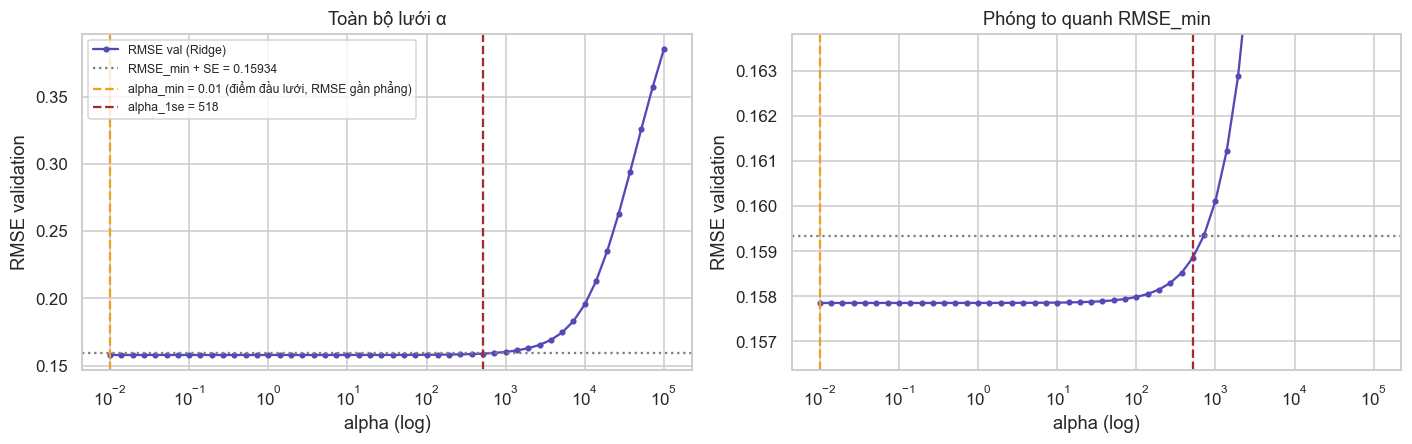

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, zoom in zip(axes, (False, True)):
    ax.plot(alpha_df["alpha"], alpha_df["RMSE"], "o-", ms=3, color="#534AB7", label="RMSE val (Ridge)")
    ax.axhline(sel["threshold"], color="grey", ls=":", label=f"RMSE_min + SE = {sel['threshold']:.5f}")
    ax.axvline(sel["alpha_min"], color="#EF9F27", ls="--", label=f"alpha_min = {sel['alpha_min']:.3g} (điểm đầu lưới, RMSE gần phẳng)")
    ax.axvline(sel["alpha_1se"], color="#A32D2D", ls="--", label=f"alpha_1se = {sel['alpha_1se']:.3g}")
    ax.set_xscale("log")
    ax.set(xlabel="alpha (log)", ylabel="RMSE validation",
           title="Toàn bộ lưới α" if not zoom else "Phóng to quanh RMSE_min")
    if zoom:
        ax.set_ylim(sel["rmse_min"] - se, sel["rmse_min"] + 4 * se)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "ridge_5_5_alpha_rmse.png")
plt.show()

### 5.6 ‖β‖ theo α

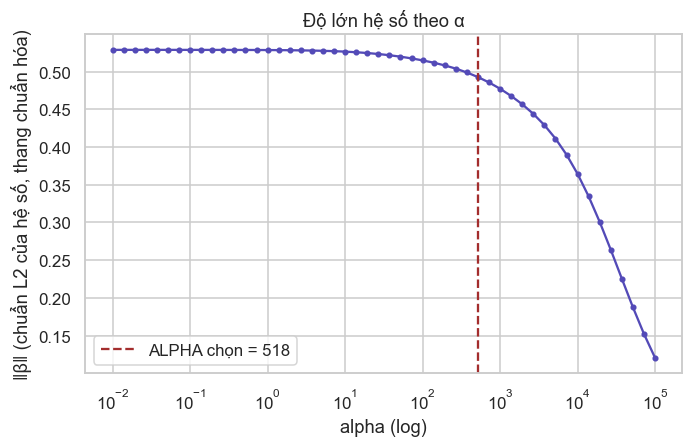

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(alpha_df["alpha"], alpha_df["coef_norm"], "o-", ms=3, color="#534AB7")
ax.axvline(ALPHA, color="#A32D2D", ls="--", label=f"ALPHA chọn = {ALPHA:.3g}")
ax.set_xscale("log")
ax.set(xlabel="alpha (log)", ylabel="‖β‖ (chuẩn L2 của hệ số, thang chuẩn hóa)", title="Độ lớn hệ số theo α")
ax.legend()
fig.savefig(FIG / "ridge_5_6_coef_norm.png")
plt.show()

### 5.7 Nhận xét: 




- Khi α tăng từ 0.01 lên 1, RMSE validation giữ nguyên ở 0.15785 (bằng OLS có clip) và ‖β‖ chỉ giảm từ 0.52889 xuống 0.52863 (khoảng 0.05%). Trong toàn vùng α ≤ 100, RMSE chỉ dao động 0.00013. Tuy nhiên từ α = 1000, RMSE tăng rõ (0.16011) và đạt 0.38528 tại α = 100 000, đây là dấu hiệu của underfitting.
- `alpha_min` = 0.01 nằm ở biên dưới của lưới, trong vùng RMSE gần phẳng, nên không phải một điểm tối ưu rõ ràng mà cho thấy Ridge không cải thiện RMSE so với OLS. Ta dùng quy tắc 1-SE (ngưỡng = 0.15934) để chọn α = 517.9, ưu tiên hệ số co mạnh hơn để giảm dao động. Do đó, RMSE tăng 0.00100 (khoảng 0.6%), nhỏ hơn 1 SE nhưng gấp khoảng 6 lần SE ghép cặp (0.00017), nên đây là mức suy giảm nhỏ nhưng nhất quán. Độ ổn định hệ số được kiểm tra ở 6.1.

## Phần 6 - Vì sao chọn Ridge Regression?


### 6.1 Bootstrap độ ổn định hệ số

Lặp `CONFIG["n_boot_train"]` lần: lấy mẫu lại train có hoàn lại, fit OLS và Ridge(α đã chọn ở 5.3), lưu hệ số.

In [29]:
rng = np.random.default_rng(SEED)
feats = list(coef_path.columns)
rows = []
for b in range(CONFIG["n_boot_train"]):
    idx = rng.integers(0, len(train), len(train))
    Xb, yb = Xtr.iloc[idx], ytr.iloc[idx]
    for name, est in (("OLS", LinearRegression()), ("Ridge", Ridge(alpha=ALPHA))):
        m = make_model(est, CONFIG).fit(Xb, yb)
        assert list(m.named_steps["prep"].get_feature_names_out()) == feats, "mau bootstrap lam mat mot muc one-hot"
        rows.append({"model": name, "b": b, **dict(zip(feats, m.named_steps["model"].coef_))})
boot = pd.DataFrame(rows)
boot.to_csv(RES / "bootstrap_coef.csv", index=False)
print("Đã lưu", RES / "bootstrap_coef.csv", boot.shape, f"| ALPHA = {ALPHA:.4g}")

Đã lưu /Users/thaihoang78/Workspace/04_Courses/CSC14005_Machine_Learning/ML-24KHMT2-Lab01/outputs/ridge/tables/bootstrap_coef.csv (400, 32) | ALPHA = 517.9


#### 6.1.2 SD hệ số của từng mô hình, 6.1.3 ghép với số mẫu nhóm (từ 2.3)

In [30]:
sd = boot.drop(columns="b").groupby("model").std(ddof=1).T[["OLS", "Ridge"]]
n_map = {f"{v}_{l}": n for v, l, n in group_counts.itertuples(index=False)}      # group_counts tu 2.3
assert not [f for f in sd.index if f not in n_map and f.removesuffix("_sq") not in NUM + BIN], "ten feature khong khop group_counts"
sd["n_group"] = [n_map.get(f, int(train[f].sum()) if f in BIN else len(train)) for f in sd.index]
sd["reduction"] = 1 - sd["Ridge"] / sd["OLS"]          # ty le SD giam: 0.45 = Ridge giam 45% do dao dong
mu = boot.drop(columns="b").groupby("model").mean().T
# nhieu tuong doi = SD / |he so|. SD giam chi vi he so co ve 0 thi khong phai on dinh hon
sd["rel_OLS"], sd["rel_Ridge"] = sd["OLS"] / mu["OLS"].abs(), sd["Ridge"] / mu["Ridge"].abs()
print(sd.sort_values("n_group").round(4).to_string())

model                                          OLS   Ridge  n_group  reduction  rel_OLS  rel_Ridge
Perceived_AI_Dependency_10                  0.0278  0.0053      138     0.8077   0.3312     0.3830
Perceived_AI_Dependency_9                   0.0142  0.0043      270     0.6994   0.2567     0.3391
Perceived_AI_Dependency_8                   0.0079  0.0036      622     0.5355   0.2481     0.3914
Perceived_AI_Dependency_7                   0.0071  0.0041     1211     0.4215   0.2059     0.2637
Perceived_AI_Dependency_6                   0.0043  0.0028     2460     0.3510   1.7603     0.5517
Primary_Use_Case_Direct_Answer_Generation   0.0036  0.0030     4418     0.1875   0.0566     0.0521
Major_Category_Medical                      0.0035  0.0025     4573     0.2757   0.4685     0.4486
Perceived_AI_Dependency_5                   0.0034  0.0025     4678     0.2514   0.6800     0.2581
Year_of_Study_Graduate                      0.0030  0.0024     5232     0.1782   0.0249     0.0267
Primary_Us

#### 6.1.4 Scatter: SD hệ số theo số mẫu của nhóm

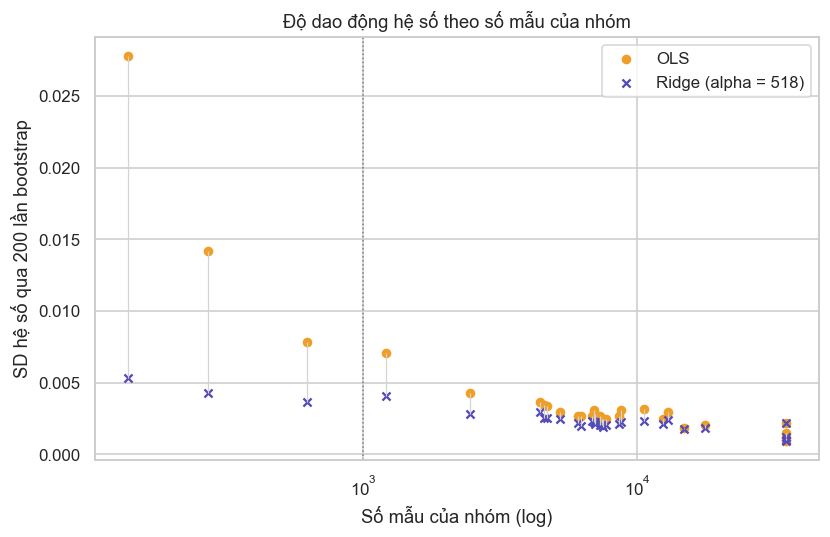

In [31]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.vlines(sd["n_group"], sd["Ridge"], sd["OLS"], color="lightgrey", lw=0.8)
ax.scatter(sd["n_group"], sd["OLS"], color="#EF9F27", s=28, label="OLS")
ax.scatter(sd["n_group"], sd["Ridge"], color="#534AB7", marker="x", s=28, label=f"Ridge (alpha = {ALPHA:.3g})")
ax.axvline(CONFIG["rare_threshold"], color="grey", ls=":", lw=1)
ax.set_xscale("log")
ax.set(xlabel="Số mẫu của nhóm (log)", ylabel=f"SD hệ số qua {CONFIG['n_boot_train']} lần bootstrap",
       title="Độ dao động hệ số theo số mẫu của nhóm")
ax.legend()
fig.savefig(FIG / "ridge_6_1_boot_sd_scatter.png")
plt.show()

#### 6.1.5 Tỷ lệ SD giảm cho các mức hiếm

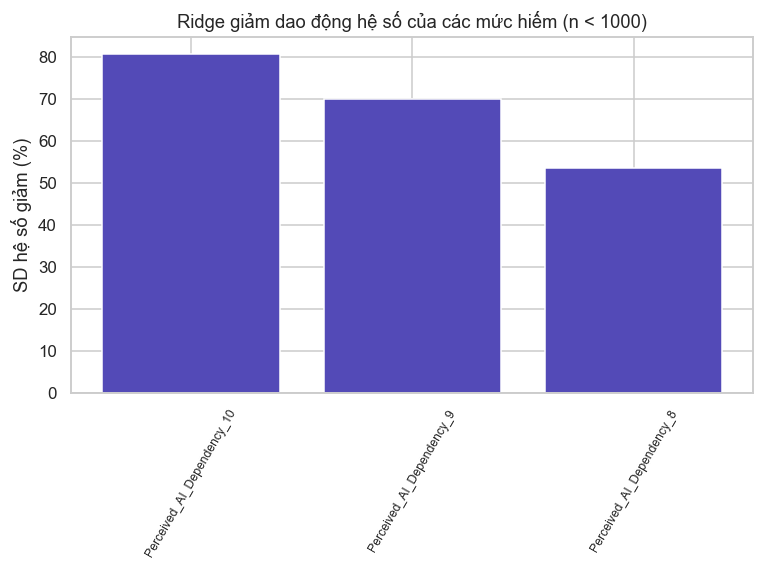

In [32]:
rare = sd[sd["n_group"] < CONFIG["rare_threshold"]].sort_values("n_group")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(rare.index, rare["reduction"] * 100, color="#534AB7")
ax.set(ylabel="SD hệ số giảm (%)", title=f"Ridge giảm dao động hệ số của các mức hiếm (n < {CONFIG['rare_threshold']})")
ax.tick_params(axis="x", rotation=60, labelsize=8)
fig.savefig(FIG / "ridge_6_1_boot_sd_reduction.png")
plt.show()

### 6.2 Learning curve

Với mỗi n và mỗi lần lặp: lấy mẫu con n dòng từ train, chọn α **nội bộ** (chia 80/20, α có RMSE nhỏ nhất trên 20% giữ lại), fit lại trên cả n dòng, đo RMSE trên validation. Validation không dùng để chọn α.

In [33]:
alphas = CONFIG["alpha_grid"]

def fit_rmse(est, Zfit, yfit, Zeval, yeval):
    p = ClippedRegressor(est, CONFIG["clip_upper"]).fit(Zfit, yfit).predict(Zeval)
    return np.sqrt(np.mean((yeval - p) ** 2))

rng = np.random.default_rng(SEED)
rows = []
with warnings.catch_warnings():
    # n nho: mau con co the thieu mot muc one-hot hiem. handle_unknown="ignore" ma hoa muc la tren val thanh toan 0
    # (dung y do, giong moi o khac); canh bao nay lap lai hang tram lan nen tat trong vong lap nay.
    warnings.simplefilter("ignore", UserWarning)
    for n in CONFIG["lc_n_grid"]:
        for rep in range(1 if n == len(train) else CONFIG["lc_n_rep"]):   # n = ca train: moi lan lap giong het nhau
            sub = rng.choice(len(train), n, replace=False)
            perm = rng.permutation(n)
            n_fit = int(CONFIG["lc_inner_train_frac"] * n)
            fit_i, hold_i = sub[perm[:n_fit]], sub[perm[n_fit:]]
            # alpha noi bo: preprocessor chi hoc tren 80% mau con
            prep_in = make_preprocessor(CONFIG).fit(Xtr.iloc[fit_i])
            Zf, Zh = prep_in.transform(Xtr.iloc[fit_i]), prep_in.transform(Xtr.iloc[hold_i])
            inner = [fit_rmse(Ridge(alpha=a), Zf, ytr_np[fit_i], Zh, ytr_np[hold_i]) for a in alphas]
            a_star = alphas[int(np.argmin(inner))]
            # fit lai tren ca n dong, do tren validation
            prep_all = make_preprocessor(CONFIG).fit(Xtr.iloc[sub])
            Zs, Zv = prep_all.transform(Xtr.iloc[sub]), prep_all.transform(Xva)
            for name, est, a in (("OLS", LinearRegression(), np.nan), ("Ridge", Ridge(alpha=a_star), a_star)):
                rows.append({"n": n, "rep": rep, "model": name, "alpha": a,
                         "RMSE": fit_rmse(est, Zs, ytr_np[sub], Zv, yva)})
lc = pd.DataFrame(rows)
lc.to_csv(RES / "learning_curve.csv", index=False)
print("Đã lưu", RES / "learning_curve.csv", lc.shape)

summ = lc.groupby(["n", "model"])["RMSE"].agg(["mean", "std", "max"]).unstack("model").fillna(0)   # n = 35.000 chi 1 lan -> std NaN -> 0
print(summ.round(4).to_string())

print(f"\nSo sánh trên validation với ALPHA đã chọn ({ALPHA:.4g}, quy tắc {CONFIG['alpha_rule']}): "
      f"Ridge = {rmse_at(ALPHA):.5f}, OLS = {metrics(yva, p_clip)['RMSE']:.5f}. "
      "6.2 chọn α khác (RMSE nhỏ nhất trên 20% giữ lại), nên hai chỗ không so trực tiếp.")


Đã lưu /Users/thaihoang78/Workspace/04_Courses/CSC14005_Machine_Learning/ML-24KHMT2-Lab01/outputs/ridge/tables/learning_curve.csv (202, 5)
         mean             std             max        
model     OLS   Ridge     OLS   Ridge     OLS   Ridge
n                                                    
100    0.1881  0.1848  0.0087  0.0099  0.2032  0.2092
200    0.1732  0.1712  0.0048  0.0047  0.1815  0.1804
500    0.1628  0.1624  0.0023  0.0019  0.1677  0.1677
1000   0.1608  0.1609  0.0012  0.0012  0.1638  0.1637
5000   0.1584  0.1584  0.0003  0.0003  0.1591  0.1591
35000  0.1579  0.1579  0.0000  0.0000  0.1579  0.1579

So sánh trên validation với ALPHA đã chọn (517.9, quy tắc 1se): Ridge = 0.15885, OLS = 0.15785. 6.2 chọn α khác (RMSE nhỏ nhất trên 20% giữ lại), nên hai chỗ không so trực tiếp.


#### 6.2.4 RMSE trung bình ± SD theo n

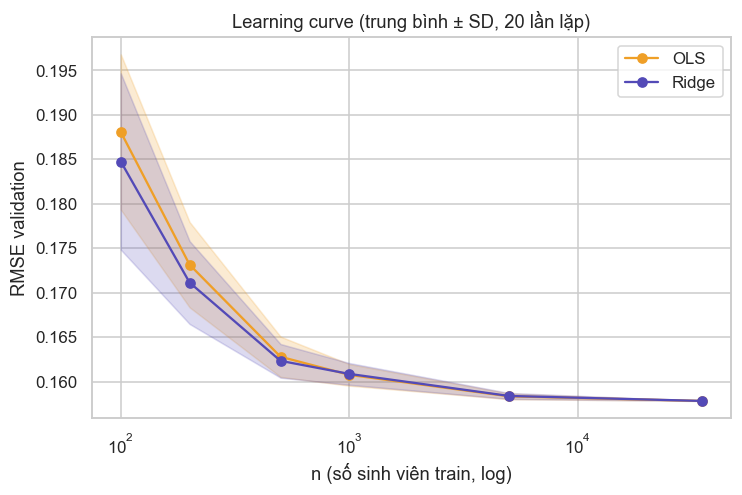

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, color in (("OLS", "#EF9F27"), ("Ridge", "#534AB7")):
    mu, s = summ[("mean", name)], summ[("std", name)]
    ax.plot(mu.index, mu, "o-", color=color, label=name)
    ax.fill_between(mu.index, mu - s, mu + s, color=color, alpha=0.2)
ax.set_xscale("log")
ax.set(xlabel="n (số sinh viên train, log)", ylabel="RMSE validation",
       title=f"Learning curve (trung bình ± SD, {CONFIG['lc_n_rep']} lần lặp)")
ax.legend()
fig.savefig(FIG / "ridge_6_2_learning_curve.png")
plt.show()

### 6.3 (Tùy chọn) Nhiều feature: **đã bỏ qua**

Bỏ qua theo lựa chọn của bạn vì A4 (ai làm polynomial/interaction) chưa chốt với nhóm. Nếu sau này nhóm chốt, thêm ô tương tác bậc 2 ở đây rồi nhớ cập nhật ô nhận xét 6.4. Hiện tại notebook **không có bằng chứng** nào về lý do "Ridge an toàn hơn khi nhiều feature".

### 6.4 Nhận xét - lý do ta chọn Ridge Regression:

- Ridge với α = 517.9 dự đoán kém OLS một chút trên validation: RMSE = 0.15885 so với 0.15785, cùng clip 4.0. Chênh lệch 0.00100 (khoảng 0.6%) nằm trong 1 SE (0.00149), nên quy tắc 1-SE vẫn chấp nhận α này. Tuy vậy, nó gấp khoảng 6 lần SE ghép cặp (0.00017), nên khó có thể chỉ do mẫu validation.

- Đổi lại, hệ số ít dao động hơn. Qua 200 lần bootstrap train, SD giảm ở cả 30 hệ số và giảm mạnh nhất ở các mức hiếm của `Perceived_AI_Dependency`: 81% ở mức 10 (138 mẫu), 70% ở mức 9 (270 mẫu), 54% ở mức 8 (622 mẫu). `Pre_Semester_GPA` chỉ giảm 1.4%, vì SD/|β| của OLS ở biến này đã chỉ là 0.005.

- SD nhỏ hơn chưa có nghĩa là hệ số đáng tin hơn. Ở cả ba mức hiếm trên, Ridge kéo hệ số về 0 nhanh hơn mức giảm SD, làm `rel` (SD/|β|) tăng (ví dụ `Perceived_AI_Dependency_10 từ 0.331 lên 0.383). `Weekly_GenAI_Hours` có đủ 35 000 dòng mà `rel` cũng tăng từ 0.246 lên 0.767, nên bias không chỉ xuất hiện ở nhóm hiếm.

- Ở learning curve 6.2, α được chọn lại theo RMSE nhỏ nhất trên từng mẫu con, nên kết quả này nói về Ridge khi ít dữ liệu, chưa phải bằng chứng cho việc chọn α = 517.9 trước đó. Ở đó RMSE trung bình của Ridge thấp hơn OLS tại n = 100 (0.1848 so với 0.1881) và n = 200 (0.1712 so với 0.1732). Từ n = 1000, hai mô hình gần như trùng nhau. Riêng ở n = 100, kết quả của Ridge lại phân tán hơn: SD 0.0099 so với 0.0087, RMSE tệ nhất 0.2092 so với 0.2032.

Ta giải thích các kết quả này bằng n = 35 000, p = 30 và đa cộng tuyến thấp: OLS đã có variance nhỏ nên Ridge còn ít chỗ để cải thiện, trong khi α lớn gây bias. Nếu mục tiêu là dự đoán trên toàn bộ dữ liệu, ta chọn OLS có clip. Ridge hợp lý khi ít dữ liệu, hoặc khi cần hệ số nhóm hiếm ít dao động và chấp nhận chúng bị kéo về 0.

## Phần 7 - Diễn giải hệ số

### 7.1 Coefficient path

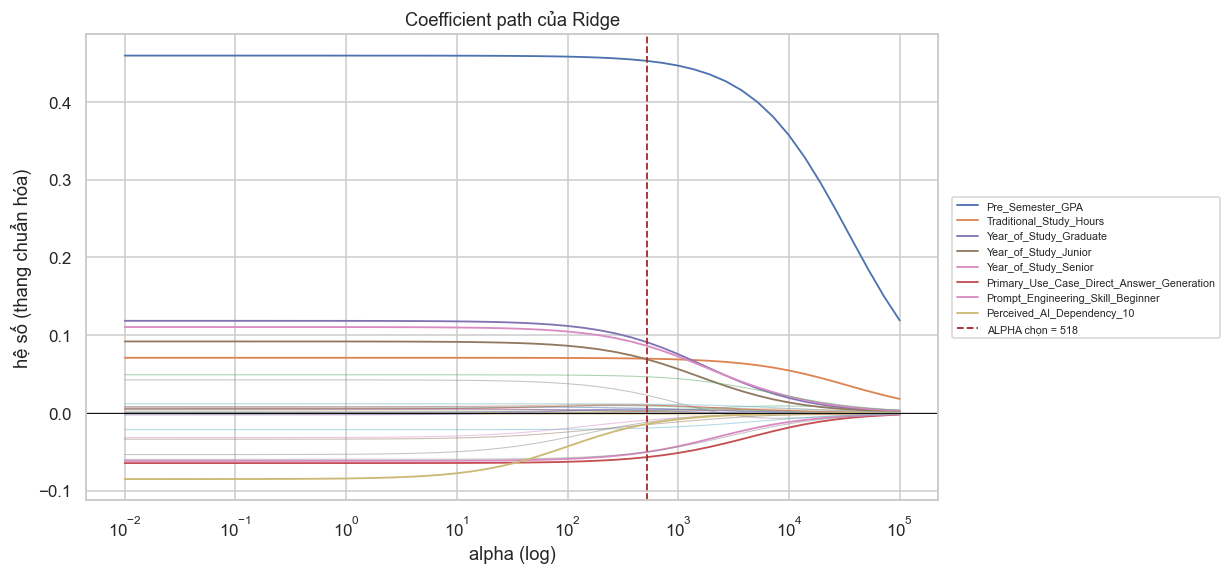

In [35]:
# coef_path (5.1): moi dong la mot alpha, moi cot la mot he so (thang chuan hoa)
top = coef_path.iloc[0].abs().nlargest(CONFIG["n_coef_path_labels"]).index   # chi dan nhan n_coef_path_labels he so lon nhat o alpha nho nhat
fig, ax = plt.subplots(figsize=(10, 5.5))
for c in coef_path.columns:
    ax.plot(coef_path.index, coef_path[c], lw=1.2 if c in top else 0.7, alpha=1 if c in top else 0.5,
            label=c if c in top else "_nolegend_")
ax.axvline(ALPHA, color="#A32D2D", ls="--", lw=1.2, label=f"ALPHA chọn = {ALPHA:.3g}")
ax.axhline(0, color="black", lw=0.6)
ax.set_xscale("log")
ax.set(xlabel="alpha (log)", ylabel="hệ số (thang chuẩn hóa)", title="Coefficient path của Ridge")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.savefig(FIG / "ridge_7_1_coef_path.png")
plt.show()

### 7.2 OLS vs Ridge: top 15 hệ số (chọn theo |hệ số OLS|)

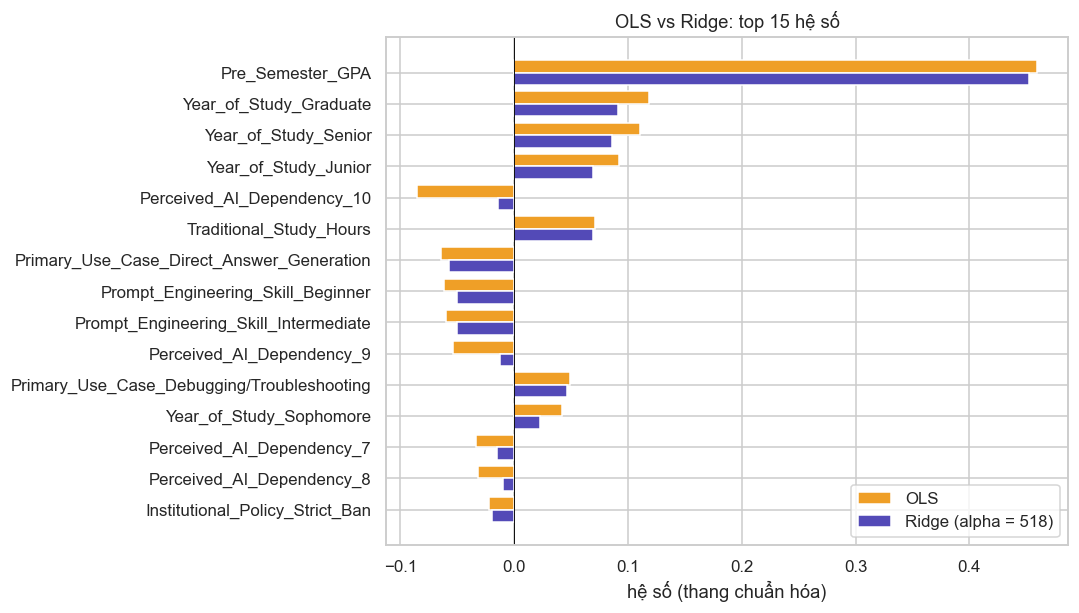

In [36]:
ols_c = pd.Series(m_clip.named_steps["model"].coef_, index=coef_path.columns)   # OLS fit tren train o 3.3
ridge_c = coef_path.loc[ALPHA]                                                  # Ridge(ALPHA) fit tren train o 5.1
top_k = ols_c.abs().nlargest(CONFIG["n_coef_bar"]).index[::-1]
pos = np.arange(len(top_k))
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(pos + 0.2, ols_c[top_k], height=0.4, color="#EF9F27", label="OLS")
ax.barh(pos - 0.2, ridge_c[top_k], height=0.4, color="#534AB7", label=f"Ridge (alpha = {ALPHA:.3g})")
ax.set_yticks(pos, top_k)
ax.axvline(0, color="black", lw=0.6)
ax.set(xlabel="hệ số (thang chuẩn hóa)", title="OLS vs Ridge: top 15 hệ số")
ax.legend()
fig.savefig(FIG / "ridge_7_2_coef_ols_vs_ridge.png")
plt.show()

### 7.3 Bảng hệ số cuối (chuẩn hóa và đơn vị gốc cho biến số)

In [37]:
# Don vi goc = he so chuan hoa / SD cua feature tren train (StandardScaler dung SD tong the, ddof=0).
sd_tr = train[NUM].std(ddof=0)
if CONFIG["genai_mode"] != "raw":
    sd_tr["Weekly_GenAI_Hours"] = np.nan      # genai_mode khac raw thi khong doi ve gio duoc
tab = pd.DataFrame({"OLS (chuẩn hóa)": ols_c, "Ridge (chuẩn hóa)": ridge_c})
tab["SD train"] = sd_tr.reindex(tab.index)
tab["OLS (đơn vị gốc)"] = tab["OLS (chuẩn hóa)"] / tab["SD train"]
tab["Ridge (đơn vị gốc)"] = tab["Ridge (chuẩn hóa)"] / tab["SD train"]
print(tab.sort_values("OLS (chuẩn hóa)", key=abs, ascending=False).round(4).to_string())

# nhom tham chieu cua one-hot: moi he so one-hot doc la chenh lech so voi nhom nay
assert CONFIG["drop_first"] and not CONFIG["scale_onehot"], "doan in nhom tham chieu chi dung voi drop_first=True, scale_onehot=False"
ohe = m_clip.named_steps["prep"].named_transformers_["cat"]
print("\nNhóm tham chiếu (bị bỏ khi drop-first):")
print(pd.Series({c: cats[0] for c, cats in zip(CAT, ohe.categories_)}).to_string())

                                            OLS (chuẩn hóa)  Ridge (chuẩn hóa)  SD train  OLS (đơn vị gốc)  Ridge (đơn vị gốc)
Pre_Semester_GPA                                     0.4595             0.4527    0.4775            0.9623              0.9480
Year_of_Study_Graduate                               0.1184             0.0911       NaN               NaN                 NaN
Year_of_Study_Senior                                 0.1104             0.0863       NaN               NaN                 NaN
Year_of_Study_Junior                                 0.0919             0.0690       NaN               NaN                 NaN
Perceived_AI_Dependency_10                          -0.0852            -0.0143       NaN               NaN                 NaN
Traditional_Study_Hours                              0.0708             0.0697    5.1615            0.0137              0.0135
Primary_Use_Case_Direct_Answer_Generation           -0.0646            -0.0570       NaN               NaN     

### 7.4 Quy tắc diễn giải hệ số

- Với biến số (`Pre_Semester_GPA`, `Traditional_Study_Hours`, `Weekly_GenAI_Hours`, `Tool_Diversity`), hệ số chuẩn hóa β là mức thay đổi của GPA dự đoán khi biến tăng 1 độ lệch chuẩn và các biến khác giữ cố định. Cột "đơn vị gốc" cho cùng ý nghĩa, nhưng tính trên 1 đơn vị gốc của biến.
- Với biến one-hot, hệ số là chênh lệch GPA dự đoán so với nhóm tham chiếu của biến đó (bảng "nhóm tham chiếu" ở 7.3), khi các biến khác giữ cố định. Hệ số của `Paid_Subscription` là chênh lệch giữa người có và không đăng ký.
- Chỉ so độ lớn hệ số giữa các biến số, vì chúng cùng thang chuẩn hóa. Hệ số one-hot đo theo đơn vị khác nên không đặt cạnh hệ số biến số để so.
- Dữ liệu là synthetic và mang tính quan sát, nên hệ số chỉ cho biết liên hệ, không cho biết nguyên nhân. Khi diễn giải, ta dùng "liên hệ với" hoặc "có liên hệ dự đoán với" thay cho "gây ra".
- So với OLS, hệ số Ridge bị kéo về 0, nhiều nhất ở nhóm hiếm. Phép co này đến từ số hạng phạt α‖β‖² mà Ridge thêm vào hàm mất mát.

### 7.5 Nhận xét

- `Pre_Semester_GPA` có hệ số chuẩn hóa lớn nhất (OLS 0.4595, Ridge 0.4527): GPA trước kỳ cao hơn 1 điểm thì GPA sau kỳ dự đoán cao hơn khoảng 0.95 điểm (Ridge, đơn vị gốc 0.9480). Trên coefficient path, hệ số này gần như không đổi đến α khoảng 1000 và vẫn còn khoảng 0.12 ở α = 100 000. Tiếp theo là `Traditional_Study_Hours` với 0.0697 mỗi độ lệch chuẩn, tức khoảng 0.0135 điểm mỗi giờ học, và hệ số này gần như không bị co ở α = 517.9.

- So với Freshman, sinh viên năm trên có GPA dự đoán cao hơn (theo Ridge: Graduate +0.0911, Senior +0.0863, Junior +0.0690, Sophomore +0.0228). Kỹ năng prompt Beginner và Intermediate thấp hơn Advanced khoảng 0.050. Người dùng AI để tạo đáp án trực tiếp có GPA dự đoán thấp hơn nhóm Copywriting/Drafting 0.0570, còn người dùng để Debugging cao hơn 0.0464. Chính sách Strict_Ban thấp hơn Actively_Encouraged 0.0194. Ridge co các hệ số Year_of_Study khoảng 22-25%, nhiều hơn biến số, vì cột one-hot không được scale nên chịu phạt mạnh hơn.

- Ridge co mạnh nhất ở nhóm hiếm. Hệ số của `Perceived_AI_Dependency` = 10 (138 mẫu) giảm từ -0.0852 (OLS) xuống -0.0143 (Ridge), khoảng 83%; trên coefficient path, đây là hệ số được dán nhãn bắt đầu co sớm nhất, từ α khoảng 10. Các mức 9, 8 và 7 cũng giảm mạnh (-0.0536 xuống -0.0121, -0.0317 xuống -0.0094, -0.0339 xuống -0.0152), nên độ lớn của các hệ số này chưa đáng tin.

- Một số biến gần như không có liên hệ với GPA dự đoán: `Weekly_GenAI_Hours` (OLS 0.0060, Ridge 0.0015 mỗi độ lệch chuẩn), `Tool_Diversity` (OLS -0.0004, Ridge +0.0023, đổi dấu) và các mức `Major_Category` (|β| ≤ 0.008). `Paid_Subscription` cũng nhỏ (+0.0112).

- Mọi so sánh trên đều theo quy tắc ở 7.4: giữ các biến khác cố định, hệ số one-hot so với nhóm tham chiếu, và chỉ là liên hệ dự đoán.

## Phần 8 - Ablation Anxiety

Chạy lại quy trình phần 5 trên **bản sao** CONFIG với `use_anxiety = True`. `CONFIG` chính không bị sửa.

### 8.1 Chạy lại quét α với Anxiety

In [38]:
cfg_anx = {**CONFIG, "use_anxiety": True}
df_anx, preds_anx, _ = sweep(cfg_anx)
se_anx = rmse_se(preds_anx[df_anx["RMSE"].idxmin()])
sel_anx = pick_alpha(df_anx, se_anx, CONFIG["alpha_rule"])
assert CONFIG["use_anxiety"] is False       # CONFIG chinh khong bi dong vao
print(f"Có Anxiety: alpha_min = {sel_anx['alpha_min']:.4g}, alpha_1se = {sel_anx['alpha_1se']:.4g}, "
      f"alpha chọn ({CONFIG['alpha_rule']}) = {sel_anx['alpha']:.4g}, SE = {sel_anx['se']:.5f}")

Có Anxiety: alpha_min = 0.01, alpha_1se = 517.9, alpha chọn (1se) = 517.9, SE = 0.00150


### 8.2 Bảng: có / không Anxiety

In [39]:
def summary_row(df, s):
    r = df.loc[df["alpha"] == s["alpha"]].iloc[0]
    return {"alpha chọn": s["alpha"], "alpha_min": s["alpha_min"], "SE": s["se"], "RMSE val": r["RMSE"], "R2 val": r["R2"]}

tab8 = pd.DataFrame({"Không Anxiety (bản chính)": summary_row(alpha_df, sel),
                     "Có Anxiety": summary_row(df_anx, sel_anx)}).T
print(tab8.round(5))
d_rmse = tab8.loc["Có Anxiety", "RMSE val"] - tab8.loc["Không Anxiety (bản chính)", "RMSE val"]
d_r2 = tab8.loc["Có Anxiety", "R2 val"] - tab8.loc["Không Anxiety (bản chính)", "R2 val"]
print(f"\nΔRMSE (có - không) = {d_rmse:+.5f}  (âm = có Anxiety tốt hơn) | ΔR2 = {d_r2:+.5f}")
print(f"Để so sánh: SE của RMSE val = {sel['se']:.5f} (bản chính), {sel_anx['se']:.5f} (có Anxiety)")
i_a = int(np.flatnonzero(alpha_df["alpha"] == sel["alpha"])[0])
i_b = int(np.flatnonzero(df_anx["alpha"] == sel_anx["alpha"])[0])
print(f"SE ghép cặp của ΔRMSE (đúng thước đo để so hai mô hình) = {rmse_se(preds_anx[i_b], alpha_preds[i_a]):.5f}")


                           alpha chọn  alpha_min       SE  RMSE val   R2 val
Không Anxiety (bản chính)   517.94747       0.01  0.00149   0.15885  0.89802
Có Anxiety                  517.94747       0.01  0.00150   0.15877  0.89813

ΔRMSE (có - không) = -0.00009  (âm = có Anxiety tốt hơn) | ΔR2 = +0.00012
Để so sánh: SE của RMSE val = 0.00149 (bản chính), 0.00150 (có Anxiety)
SE ghép cặp của ΔRMSE (đúng thước đo để so hai mô hình) = 0.00005


### 8.3 Nhận xét: 

- Mô hình được dùng để dự đoán trước kỳ thi, khi mức lo âu trong kỳ thi chưa thể biết, nên ta không dùng `Anxiety_Level_During_Exams`. Việc loại biến này chỉ làm RMSE validation tăng 0.00009 (từ 0.15877 lên 0.15885), gần như không ảnh hưởng đến độ chính xác.

## Phần 9 - TESTING


In [40]:
# 9.1 thoi diem chay va cau hinh dung cho test
RUN_AT = datetime.now().isoformat(timespec="seconds")
ALPHA_ANX = sel_anx["alpha"]
print("Chạy test lúc:", RUN_AT)
print("CONFIG:", {k: ("..." if k == "alpha_grid" else v) for k, v in CONFIG.items()})
print(f"ALPHA bản chính = {ALPHA:.4g} | ALPHA bản có Anxiety = {ALPHA_ANX:.4g}")

Chạy test lúc: 2026-11-25T22:55:26
CONFIG: {'use_anxiety': False, 'drop_first': True, 'scale_onehot': False, 'genai_mode': 'raw', 'alpha_grid': '...', 'alpha_rule': '1se', 'clip_upper': 4.0, 'refit_on_trval': False, 'n_boot_train': 200, 'n_boot_val': 500, 'expected_n_rows': (35000, 7500, 7500), 'gpa_cap': 4.0, 'gpa_cap_frac_range': (0.09, 0.1), 'rare_threshold': 1000, 'n_top_corr': 10, 'vif_threshold': 5, 'n_deciles': 10, 'ref_pearson_pre': 0.92641, 'tol_pearson_pre': 0.0005, 'ref_max_vif': 2.77, 'ref_cond_std': 4.32, 'tol_vif_cond': 0.05, 'ref_skew_genai': 1.61, 'tol_baseline_r2': 0.01, 'gate3_rmse_range': (0.157, 0.1605), 'ref_e3_rmse': 0.157, 'lc_n_grid': [100, 200, 500, 1000, 5000, 35000], 'lc_n_rep': 20, 'lc_inner_train_frac': 0.8, 'n_coef_path_labels': 8, 'n_coef_bar': 15}
ALPHA bản chính = 517.9 | ALPHA bản có Anxiety = 517.9


### 9.2 - 9.3 Fit và dự đoán trên test

In [41]:
y_test = pd.read_csv(FILES["test"])[TARGET].to_numpy()      # lan duy nhat target cua test duoc doc
assert len(y_test) == len(test)
UP = CONFIG["clip_upper"]
assert UP is not None, "phan 9 so sanh co/khong clip: can CONFIG['clip_upper']"

# D8: fit lai tren train + val neu refit_on_trval
fit_df = pd.concat([train, val], ignore_index=True) if CONFIG["refit_on_trval"] else train
print("Fit trên:", "train + val" if CONFIG["refit_on_trval"] else "train", f"({len(fit_df)} dòng)")

RIDGE = f"Ridge (alpha = {ALPHA:.4g})"
specs = {"Mean baseline": (DummyRegressor(strategy="mean"), False),
         "OLS": (LinearRegression(), False),
         RIDGE: (Ridge(alpha=ALPHA), False),
         f"Ridge + Anxiety (alpha = {ALPHA_ANX:.4g})": (Ridge(alpha=ALPHA_ANX), True)}
test_pred = {}      # du doan KHONG clip; ban clip = np.minimum(p, UP) (da kiem o 3.3)
for name, (est, anx) in specs.items():
    m = make_model(est, {**CONFIG, "use_anxiety": anx, "clip_upper": None}).fit(make_X(fit_df, anx), fit_df[TARGET])
    test_pred[name] = m.predict(make_X(test, anx))
print("Đã dự đoán:", ", ".join(test_pred))

Fit trên: train (35000 dòng)


Đã dự đoán:

 Mean baseline, OLS, Ridge (alpha = 517.9), Ridge + Anxiety (alpha = 517.9)


### 9.4 Bảng MAE / MSE / RMSE / R² trên test (không clip và có clip)

In [42]:
rows = {}
for name, p in test_pred.items():
    rows[(name, "không clip")] = metrics(y_test, p)
    rows[(name, f"clip {UP}")] = metrics(y_test, np.minimum(p, UP))
tab9 = pd.DataFrame(rows).T
print(tab9.round(5).to_string())

p_main = np.minimum(test_pred[RIDGE], UP)       # Ridge ban chinh, co clip: dung cho 9.5 - 9.7
resid = y_test - p_main

                                                MAE      MSE     RMSE       R2
Mean baseline                   không clip  0.40627  0.24738  0.49737 -0.00000
                                clip 4.0    0.40627  0.24738  0.49737 -0.00000
OLS                             không clip  0.12547  0.02549  0.15966  0.89695
                                clip 4.0    0.12033  0.02460  0.15684  0.90056
Ridge (alpha = 517.9)           không clip  0.12578  0.02571  0.16033  0.89608
                                clip 4.0    0.12148  0.02501  0.15815  0.89890
Ridge + Anxiety (alpha = 517.9) không clip  0.12580  0.02570  0.16030  0.89612
                                clip 4.0    0.12149  0.02500  0.15811  0.89894


### 9.5 Dự đoán vs thực tế (Ridge bản chính, có clip)

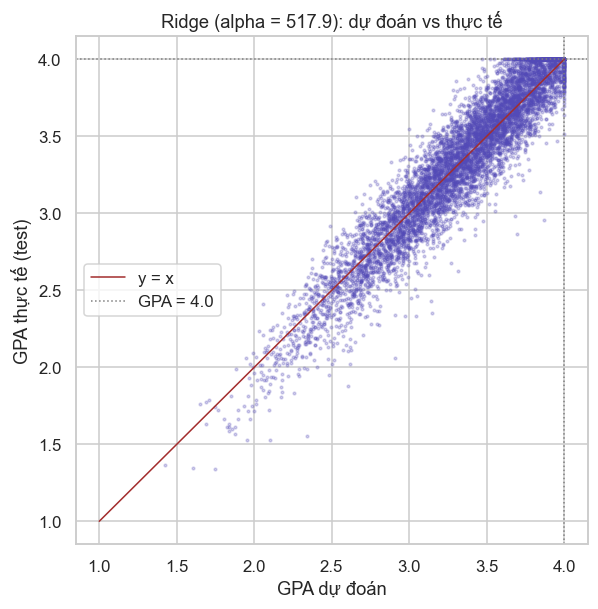

In [43]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(p_main, y_test, s=3, alpha=0.25, color="#534AB7")
ax.plot([1, 4], [1, 4], color="#A32D2D", lw=1, label="y = x")
ax.axhline(CONFIG["gpa_cap"], color="grey", ls=":", lw=1, label=f"GPA = {CONFIG['gpa_cap']}")
ax.axvline(CONFIG["gpa_cap"], color="grey", ls=":", lw=1)
ax.set(xlabel="GPA dự đoán", ylabel="GPA thực tế (test)", title=f"{RIDGE}: dự đoán vs thực tế")
ax.legend()
fig.savefig(FIG / "ridge_9_5_pred_vs_actual.png")
plt.show()

### 9.6 Phần dư vs dự đoán

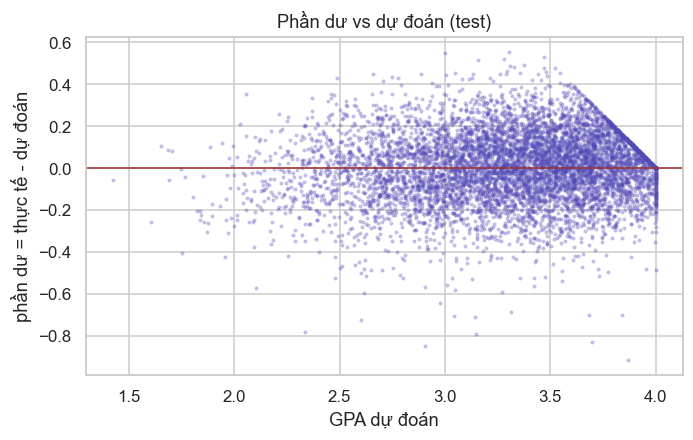

In [44]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(p_main, resid, s=3, alpha=0.25, color="#534AB7")
ax.axhline(0, color="#A32D2D", lw=1)
ax.set(xlabel="GPA dự đoán", ylabel="phần dư = thực tế - dự đoán", title="Phần dư vs dự đoán (test)")
fig.savefig(FIG / "ridge_9_6_resid_vs_pred.png")
plt.show()

### 9.7 Histogram phần dư

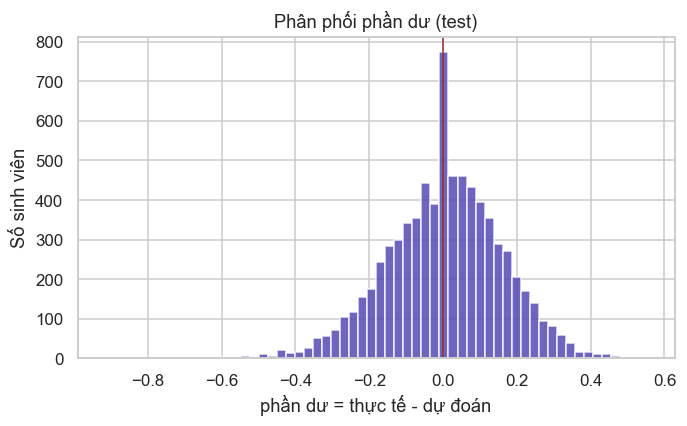

Phần dư: mean = +0.0037, SD = 0.1581, min = -0.916, max = 0.554


In [45]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(resid, bins=60, color="#534AB7", alpha=0.85)
ax.axvline(0, color="#A32D2D", lw=1)
ax.set(xlabel="phần dư = thực tế - dự đoán", ylabel="Số sinh viên", title="Phân phối phần dư (test)")
fig.savefig(FIG / "ridge_9_7_resid_hist.png")
plt.show()
print(f"Phần dư: mean = {resid.mean():+.4f}, SD = {resid.std(ddof=1):.4f}, min = {resid.min():.3f}, max = {resid.max():.3f}")

### 9.8 Nhận xét: 

- Trên test (có clip 4.0), Ridge với α = 517.9 đạt RMSE 0.15815 và R² 0.89890, kém OLS (0.15684 và 0.90056) khoảng 0.00131, tức 0.8%. Trên validation Ridge cũng kém OLS 0.00100, nên hai tập cho cùng kết luận. Ta chưa tính SE cho chênh lệch trên test, vì vậy chỉ nói được về chiều và độ lớn của nó.

- RMSE test thấp hơn validation một chút ở cả hai mô hình (Ridge 0.15815 so với 0.15885, OLS 0.15684 so với 0.15785), nên không thấy dấu hiệu overfit. Cả hai vượt xa mean baseline (RMSE 0.49737, R² ≈ 0). Bước clip có tác dụng lớn hơn việc chọn giữa Ridge và OLS: nó đưa RMSE của Ridge từ 0.16033 xuống 0.15815.

- Gần GPA = 4.0, biểu đồ 9.5 có một dải dọc tại dự đoán = 4.0 (các dự đoán bị clip) và một dải ngang tại GPA thực tế = 4.0 (target chạm trần). Vì GPA thực tế không vượt 4.0, phần dư luôn nhỏ hơn hoặc bằng 4.0 trừ dự đoán; ở 9.6 giới hạn này hiện thành một đường chéo chặn trên các điểm có dự đoán từ khoảng 3.6 trở lên.

- Phần dư có trung bình +0.0037 và SD 0.1581, gần bằng RMSE. Phân phối gần đối xứng, nhưng đuôi trái dài hơn đuôi phải (min -0.916, max 0.554), nghĩa là có lúc mô hình dự đoán cao hơn thực tế khá nhiều. Cột nhọn ở 0 là các sinh viên có GPA thực tế = 4.0 và dự đoán bị clip về đúng 4.0.

- Thêm Anxiety chỉ làm RMSE test giảm 0.00004 (0.15811 so với 0.15815), không đủ để đổi quyết định loại biến này (D2).

## Phần 10 - Xuất cho App

Xuất mô hình chính cho App: Ridge với α đã chọn ở 5.3, fit trên `fit_df` của 9.2, có clip, không Anxiety. Chạy sau phần 9 vì dùng `ALPHA`, `fit_df`, `tab9`, `p_main`, `RUN_AT`.

Lưu ý cho App:
- Pipeline chứa `ClippedRegressor` (và `GenAIPoly` nếu đổi `genai_mode`), nên `joblib.load` cần import được `lab01_ml.models.ridge` (`src/lab01_ml/models/ridge.py`) và cùng phiên bản scikit-learn (`metadata.json`: 1.8.0).
- Đầu vào là DataFrame 1 dòng, đúng các cột trong `metrics.json["features"]`: 11 cột khi `use_anxiety = False` (task ghi 12 là tính cả Anxiety).
- Schema `metrics.json` chưa được nhóm chốt (A5). Đang dùng các key mẫu trong `task_check.md` (`model`, `alpha`, `rmse_val`, `r2_val`, `rmse_test`, `run_date`) cộng thêm vài key; cần đối chiếu với người làm App.

### 10.1 Lưu pipeline

In [46]:
# Mo hinh chinh: tien xu ly + Ridge(ALPHA) + clip(clip_upper). Fit tren fit_df (D8), khong Anxiety (D2).
USE_ANX = CONFIG["use_anxiety"]
final_model = make_model(Ridge(alpha=ALPHA), CONFIG).fit(make_X(fit_df, USE_ANX), fit_df[TARGET])
MODEL_PATH = MODELS / "ridge_pipeline.joblib"
joblib.dump(final_model, MODEL_PATH)
print("Đã lưu", MODEL_PATH.relative_to(ROOT), f"({MODEL_PATH.stat().st_size / 1024:.1f} KB)")

Đã lưu outputs/ridge/models/ridge_pipeline.joblib (6.4 KB)


### 10.2 Ghi `outputs/ridge/metrics.json`

In [47]:
r_val = alpha_df.loc[alpha_df["alpha"] == ALPHA].iloc[0]       # metric val (co clip) tu 5.1
r_test = tab9.loc[(RIDGE, f"clip {UP}")]                      # metric test (co clip) tu 9.4
metrics_out = {
    "model": "ridge",
    "alpha": float(ALPHA),
    "alpha_rule": CONFIG["alpha_rule"],
    "clip_upper": UP,
    "features": list(make_X(train, USE_ANX).columns),
    "n_fit": len(fit_df),
    "rmse_val": float(r_val["RMSE"]), "r2_val": float(r_val["R2"]),
    "rmse_test": float(r_test["RMSE"]), "r2_test": float(r_test["R2"]),
    "run_date": RUN_AT,
    "config": CONFIG,
}
with open(OUT / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_out, f, ensure_ascii=False, indent=2, default=lambda o: o.tolist())   # ndarray / np.float -> list / float
print("Đã lưu", (OUT / "metrics.json").relative_to(ROOT))
print({k: v for k, v in metrics_out.items() if k not in ("config", "features")})

Đã lưu outputs/ridge/metrics.json
{'model': 'ridge', 'alpha': 517.9474679231213, 'alpha_rule': '1se', 'clip_upper': 4.0, 'n_fit': 35000, 'rmse_val': 0.1588549968925703, 'r2_val': 0.8980156856276329, 'rmse_test': 0.15814759594421932, 'r2_test': 0.8988973627254468, 'run_date': '2026-11-25T22:55:26'}


### 10.3 Test nhanh: load lại pipeline

In [48]:
loaded = joblib.load(MODEL_PATH)
assert loaded.named_steps["model"].upper == UP, "clip khong nam trong pipeline da luu"

i_row = int(np.flatnonzero(p_main < UP)[0])                    # dong dau tien khong bi clip, de vi du co y nghia
row = test.iloc[i_row][metrics_out["features"]].to_dict()      # 1 dong raw dict (dung cac feature dau vao cua mo hinh)
print(row)
pred_one = float(loaded.predict(pd.DataFrame([row]))[0])
print(f"GPA dự đoán cho 1 dòng raw dict: {pred_one:.4f}")
assert np.isfinite(pred_one) and pred_one <= UP
assert np.isclose(pred_one, p_main[i_row])

# khop du doan truoc khi luu (p_main tu 9.4, tinh bang mo hinh fit o 9.2 roi clip tay)
assert np.allclose(loaded.predict(make_X(test, USE_ANX)), p_main)
print("Pipeline load lại khớp dự đoán trước khi lưu ✓")

{'Pre_Semester_GPA': 3.42, 'Traditional_Study_Hours': 2.87, 'Weekly_GenAI_Hours': 2.0, 'Tool_Diversity': 2, 'Paid_Subscription': 1, 'Year_of_Study': 'Sophomore', 'Major_Category': 'Business', 'Primary_Use_Case': 'Debugging/Troubleshooting', 'Prompt_Engineering_Skill': 'Beginner', 'Institutional_Policy': 'Strict_Ban', 'Perceived_AI_Dependency': 1}
GPA dự đoán cho 1 dòng raw dict: 3.4736
Pipeline load lại khớp dự đoán trước khi lưu ✓


### 10.4 Lưu coefficient path cho thanh trượt α của App

In [49]:
# coef_path (5.1): moi dong la mot alpha, moi cot la mot he so (thang chuan hoa)
coef_path.to_csv(RES / "coef_path.csv", index_label="alpha")
print("Đã lưu", (RES / "coef_path.csv").relative_to(ROOT), coef_path.shape)

Đã lưu outputs/ridge/tables/coef_path.csv (50, 30)
